# Human or AI? — Group Number 1


This notebook contains all code for feature extraction, controlled experiments, final training and prediction. It uses no custom helper functions or companion Python scripts. Question headings follow the course report template.

**Scored reference run:** `89edcbdd288ce05a`, Tesla T4, fixed validation AUROC **0.999391**, public AUROC **0.98819** reported by the team. **Saved outputs in this notebook:** rerun `3bd0a8a7c0bd60ce` (Tesla T4, same validation AUROC **0.999391**), except the TF-IDF baseline table and the Q1 comparison figure, which were produced in a separate CPU session from the same `train.csv`, split and folds. 29 of the 30 code cells have saved outputs (the historical-metadata cell prints nothing), and none is an error.



## Group Information

**Group Number:** 1  
**Kaggle Team Name:** Group Number 1

| Name | NetID |
|---|---|
| Alina Patel | ap2599 |
| Haoxiang Zhang | hz795 |
| Tim Eilers | te228 |

### Contributions

All three members jointly contributed to data preparation, model
development, experimentation, evaluation, and report writing.

## Setup — Data, dependencies and execution
**Data provenance.** Download the competition's five supplied files from the Kaggle competition Data tab: `train.csv`, `test.csv`, `unlabeled.csv`, `train_starter_2000.csv`, and `sample_submission.csv`. The starter file is a subset of training data, not additional labels. No external labeled authorship data or hidden test labels are used.

**Colab steps:** select **Runtime → Change runtime type → T4 GPU**, run the dependency cell and restart only if it requests it. Place the CSVs in `MyDrive/human_or_ai/data/` or set `DATA_FOLDER` in the setup cell to their actual folder. The default Drive folder is a convenience, not a course requirement. Run all cells in order.

**Execution and reproducibility.** Seed 42 controls the split, five-fold CV and estimators. First runs compute all features and fit all classifiers. `REUSE_CURRENT_RUN=True` resumes only matching artifacts created by this workflow. Set `HUMAN_AI_REUSE=0` before a terminal run to recompute. Outputs default to `human_or_ai/outputs/full_colab_training/`, preserving existing compatible caches. The scored reference run used Python 3.13.16, NumPy 2.4.6, pandas 2.2.3, SciPy 1.16.3, scikit-learn 1.6.1, CatBoost 1.2.8, PyTorch 2.11.0+cu130, transformers 4.57.1 and tokenizers 0.22.2; the saved outputs come from a rerun with the same versions except PyTorch 2.14.1+cu130, as printed by the setup cell. Exact cross-environment numerical identity is not assumed.

GPT-2/Pythia use CUDA in the reference run; classifiers and PCA use CPU. Local CUDA is selected automatically when available, otherwise local execution uses CPU and can be much slower. Local commands are provided in Q6.1.


In [ ]:
import sys, subprocess, importlib.metadata
from packaging.requirements import Requirement

# Install before importing the modeling libraries; retain Colab's CUDA PyTorch.
requirements = [
    'numpy>=1.26,<3', 'pandas>=2.2,<3', 'scipy>=1.11,<2',
    'scikit-learn==1.6.1', 'catboost==1.2.8', 'matplotlib>=3.5,<4',
    'joblib>=1.4,<2', 'threadpoolctl>=3.5,<4', 'transformers==4.57.1',
    'tokenizers>=0.22,<0.24', 'safetensors>=0.4,<1',
]
watched = {'numpy':'numpy','pandas':'pandas','scipy':'scipy','scikit-learn':'sklearn',
    'catboost':'catboost','transformers':'transformers','tokenizers':'tokenizers',
    'huggingface-hub':'huggingface_hub','safetensors':'safetensors',
    'matplotlib':'matplotlib','joblib':'joblib','threadpoolctl':'threadpoolctl'}
loaded_versions = {}
for package, module in watched.items():
    if module in sys.modules:
        try:
            loaded_versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
needed = []
for specification in requirements:
    requirement = Requirement(specification)
    try:
        installed = importlib.metadata.version(requirement.name)
    except importlib.metadata.PackageNotFoundError:
        needed.append(specification)
    else:
        if not requirement.specifier.contains(installed, prereleases=True):
            needed.append(specification)
if needed:
    print('Installing:', needed, flush=True)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *needed])
else:
    print('Required package versions are already available.')
changed_loaded = [package for package, old_version in loaded_versions.items()
                  if importlib.metadata.version(package) != old_version]
if changed_loaded:
    raise RuntimeError(
        f'Updated libraries were already loaded: {changed_loaded}. '
        'Choose Runtime → Restart session, then run this notebook from the beginning.')
try:
    print('Colab PyTorch:', importlib.metadata.version('torch'))
except importlib.metadata.PackageNotFoundError:
    raise RuntimeError('Install PyTorch in the local environment, or start a standard Colab GPU runtime.')
print('Dependencies ready. Continue to the GPU check.')


Required package versions are already available.
Colab PyTorch: 2.14.1+cu130
Dependencies ready. Continue to the GPU check.


In [ ]:
from pathlib import Path
import sys, os, json, hashlib, random, time, warnings, re, unicodedata, gc
from collections import Counter
from importlib.util import find_spec

# Paths can be edited here or supplied as environment variables for a terminal run.
try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True
PROJECT_FOLDER = os.environ.get('HUMAN_AI_PROJECT_DIR',
    '/content/drive/MyDrive/human_or_ai' if IN_COLAB else str(Path.cwd()))
DATA_FOLDER = os.environ.get('HUMAN_AI_DATA_DIR')  # None uses PROJECT_FOLDER/data or Data.
OUTPUT_FOLDER = os.environ.get('HUMAN_AI_OUTPUT_DIR')  # None preserves the original output folder.
DEVICE_PREFERENCE = os.environ.get('HUMAN_AI_DEVICE', 'cuda' if IN_COLAB else 'auto')
REUSE_CURRENT_RUN = os.environ.get('HUMAN_AI_REUSE', '1') == '1'
DOWNLOAD_SUBMISSION = IN_COLAB
LOCAL_WEIGHTS_ONLY = False  # True forbids weight/tokenizer downloads.
MODEL_LOCATIONS = {'gpt2': None, 'pythia': None}  # Optional folders containing public weights.
EXPERIMENT_VERSION = 'full_colab_procedural_v1'  # Bump after changing formulas or training logic.
SEED = 42
CPU_THREADS = 2
SHARD_ROWS = 128

packages = ['numpy','pandas','scipy','sklearn','catboost','matplotlib',
            'joblib','threadpoolctl','torch','transformers','tokenizers','safetensors']
missing = [name for name in packages if find_spec(name) is None]
if missing:
    raise ImportError(f'Missing packages: {missing}. Run the Colab dependency cell above.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn, catboost, joblib, torch, transformers, tokenizers
from IPython.display import display
from scipy.sparse import csr_matrix, hstack, vstack
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, Normalizer, PolynomialFeatures, normalize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, log_loss, confusion_matrix
from catboost import CatBoostClassifier
from transformers import AutoTokenizer, AutoModelForCausalLM
from tokenizers import Tokenizer, models, pre_tokenizers, trainers
from threadpoolctl import threadpool_limits

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(CPU_THREADS)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
if DEVICE_PREFERENCE not in ['auto','cuda','cpu']:
    raise ValueError('HUMAN_AI_DEVICE must be auto, cuda or cpu.')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') if DEVICE_PREFERENCE == 'auto' else torch.device(DEVICE_PREFERENCE)
if device.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. In Colab choose Runtime → Change runtime type → T4 GPU; locally select cpu if needed.')
ENVIRONMENT = {'python':sys.version,'numpy':np.__version__,'pandas':pd.__version__,
    'scipy':scipy.__version__,'scikit_learn':sklearn.__version__,'catboost':catboost.__version__,
    'torch':torch.__version__,'transformers':transformers.__version__,'tokenizers':tokenizers.__version__,
    'device':str(device),'device_name':torch.cuda.get_device_name() if device.type=='cuda' else str(device)}
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
display(pd.DataFrame(ENVIRONMENT.items(),columns=['Setting','Value']))
print('Feature extraction device:', ENVIRONMENT['device_name'])
print('Classifiers and PCA use CPU. First-run CPU feature extraction can be slow.')


,Setting,Value
0,python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
1,numpy,2.4.6
2,pandas,2.2.3
3,scipy,1.16.3
4,scikit_learn,1.6.1
5,catboost,1.2.8
6,torch,2.14.1+cu130
7,transformers,4.57.1
8,tokenizers,0.22.2
9,device,cuda


Feature extraction device: Tesla T4
Classifiers and PCA use CPU. First-run CPU feature extraction can be slow.


In [ ]:
# Download the five supplied competition CSVs from Kaggle before this step.
if IN_COLAB and (str(PROJECT_FOLDER).startswith('/content/drive/') or
                 any(str(p).startswith('/content/drive/') for p in [DATA_FOLDER, OUTPUT_FOLDER] if p)):
    drive.mount('/content/drive')
PROJECT_DIR = Path(PROJECT_FOLDER).expanduser().resolve()
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(f'Project folder is missing: {PROJECT_DIR}. Set PROJECT_FOLDER in Setup.')
DATA_DIR = Path(DATA_FOLDER).expanduser().resolve() if DATA_FOLDER else next(
    (PROJECT_DIR/d for d in ['Data','data'] if (PROJECT_DIR/d/'train.csv').is_file()),None)
if DATA_DIR is None or not DATA_DIR.is_dir():
    raise FileNotFoundError('Set DATA_FOLDER to the folder containing the five Kaggle CSVs, or put them in data/.')
OUTPUT_ROOT = Path(OUTPUT_FOLDER).expanduser().resolve() if OUTPUT_FOLDER else PROJECT_DIR/'outputs/full_colab_training'
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
file_names = ['train.csv','test.csv','unlabeled.csv','train_starter_2000.csv','sample_submission.csv']
missing = [name for name in file_names if not (DATA_DIR/name).is_file()]
if missing:
    raise FileNotFoundError(f'Missing competition files: {missing}')
datasets = {name:pd.read_csv(DATA_DIR/name) for name in file_names}
train,test,unlabeled,template = [datasets[name] for name in
    ['train.csv','test.csv','unlabeled.csv','sample_submission.csv']]
assert len(train)==10000 and set(train.label)=={0,1}
assert len(test)==len(unlabeled)==3000
assert 'label' not in test and 'label' not in unlabeled
for name,frame in datasets.items():
    assert frame.id.is_unique and frame.id.notna().all(),name
    if 'text' in frame:
        assert frame.text.notna().all() and frame.text.str.strip().ne('').all(),name
assert set(template.id)==set(test.id) and len(template.columns)==2
assert set(datasets['train_starter_2000.csv'].id)<=set(train.id)
DATA_HASHES = {name:hashlib.sha256((DATA_DIR/name).read_bytes()).hexdigest() for name in file_names}
FIT_IDS,VAL_IDS = train_test_split(train.id.to_numpy(),test_size=2000,
    stratify=train.label.to_numpy(),random_state=SEED)
indexed_train = train.set_index('id')
y_fit = indexed_train.loc[FIT_IDS,'label'].to_numpy()
y_val = indexed_train.loc[VAL_IDS,'label'].to_numpy()
assert np.bincount(y_fit).tolist()==[4000,4000] and np.bincount(y_val).tolist()==[1000,1000]
assert set(FIT_IDS).isdisjoint(VAL_IDS)
schema = pd.DataFrame([{'Dataset':name,'Rows':len(frame),'Columns':len(frame.columns),
    'Headers':', '.join(frame.columns),'File MB':(DATA_DIR/name).stat().st_size/1e6}
    for name,frame in datasets.items()])
display(schema)
print('Output root:',OUTPUT_ROOT)
print('Fixed split:',len(FIT_IDS),'training rows;',len(VAL_IDS),'validation rows')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Dataset,Rows,Columns,Headers,File MB
0,train.csv,10000,3,"id, text, label",12.748778
1,test.csv,3000,2,"id, text",3.865834
2,unlabeled.csv,3000,2,"id, text",3.841922
3,train_starter_2000.csv,2000,3,"id, text, label",2.568433
4,sample_submission.csv,3000,2,"id, label",0.030009


Output root: /content/drive/MyDrive/human_or_ai/outputs/full_colab_training
Fixed split: 8000 training rows; 2000 validation rows


## Q0 — Team information and model summary
### Q0.1 — Members and contributions
Kaggle team: **Group Number 1**. Members: **Alina Patel (ap2599)**, **Haoxiang Zhang (hz795)** and **Tim Eilers (te228)**. Course PR: https://github.com/sekhari/human-or-ai-submissions/pull/17

### Q0.2 — Final approach
We combine frozen language-model statistics, observable formatting/repetition measurements and GPT-2 contextual vectors. GPT-2 and Pythia describe how predictable each document is; supervised LR and CatBoost branches learn authorship from the supplied labels. A small earlier sparse-text LR ensemble contributes lexical evidence. A final CatBoost branch joins 122 statistics/structure features with 16 training-fitted PCA components of normalized GPT-2 vectors. Fixed weighted averaging produces an AI probability, and all supervised components are refitted on 10,000 labeled examples for the final test submission.

### Q0.3 — Recorded scores
| Metric | Reference result | Evidence |
|---|---:|---|
| Validation AUROC | 0.999391 | Fixed 2,000-row validation set; Q4.1 |
| Kaggle public AUROC | 0.98819 | Team-reported result for the preserved reference submission |
| Kaggle private AUROC | Not revealed | Leave blank until released |

The public score is linked to the preserved CSV, not automatically to every future rerun.


In [ ]:

FINAL_WEIGHTS = {'legacy_lr':.08,'structure_tree':.12,'dual_lm_tree':.05,
                 'all_features_tree':.25,'embedding_statistics_tree':.50}
assert np.isclose(sum(FINAL_WEIGHTS.values()),1.)
display(pd.DataFrame(FINAL_WEIGHTS.items(),columns=['Branch','Final weight']))



,Branch,Final weight
0,legacy_lr,0.08
1,structure_tree,0.12
2,dual_lm_tree,0.05
3,all_features_tree,0.25
4,embedding_statistics_tree,0.50


## Q1 — Model comparison and selection
### Q1.1 — Preprocessing and representation
We preserve a raw view and build a normalized view using Unicode normalization, selected punctuation mapping, case folding and whitespace normalization. Frozen GPT-2 provides 24 statistics for each view; their differences supply another 24. Twenty observable layout/repetition features and 30 frozen Pythia statistics yield 122 columns. GPT-2 also provides 768-dimensional mean-pooled token states. The joint tree uses the first 16 components of a 32-component PCA fitted only to normalized training vectors. Earlier LR branches include word/character or training-learned BPE features, NB reweighting and 37 style measurements. Keeping raw and normalized views helps retain formatting information while testing content-related signals. Frozen extraction operates independently per document; learned vocabularies, scalers and PCA are fitted only on the relevant training rows.

**Why we moved away from TF-IDF.** Our first representation was word TF-IDF (lowercased 1–2-grams, at most 50,000 features, sublinear term frequency) with logistic regression, the model family of the course's reference baseline. Q1.2 re-runs it under the same split, folds and C grid (row **TF-IDF LR**). It fits the training rows perfectly (AUROC 1.0000) but reaches only 0.9431 on validation; the course reports about 0.868 private AUROC for its reference TF-IDF baseline. Logistic regression on the 122 frozen-model statistics reaches 0.9960 on the same validation rows, with a train–validation gap of 0.0026 instead of 0.0569. N-gram counts mostly encode topic and vocabulary, which a 50,000-dimensional linear model can memorize; how predictable a text is to a pretrained language model is less tied to the training set's vocabulary. This result motivated replacing n-gram counting with normalization plus frozen-model scoring; n-gram branches remain only a small ensemble component.

#### Formatting, normalization and sparse-branch style measurements
The following formulas preserve the reference implementation, including any constant columns. Modifying them would constitute a new modeling experiment.


In [ ]:
# Build structure features for each supplied text; IDs remain attached throughout.
all_text = pd.concat([train[['id','text']], test[['id','text']], unlabeled[['id','text']]],ignore_index=True)
assert all_text.id.is_unique
TRANSLATION = str.maketrans({'’': "'", '‘': "'", '“': '"', '”': '"', '—': '-', '–': '-', '…': '...'})
normalized_texts=[]
structure_rows=[]
for t in all_text.text:
    normalized = unicodedata.normalize('NFKC', t).translate(TRANSLATION).casefold()
    normalized = ''.join(c for c in normalized if unicodedata.category(c)!='Cf')
    normalized_texts.append(' '.join(normalized.split()))
    words = re.findall("[A-Za-z]+(?:['’][A-Za-z]+)?", t.lower())
    lines = [l for l in t.splitlines() if l.strip()]
    n = max(1, len(lines))
    length = max(1, len(t))
    normlines = [' '.join(l.lower().split()) for l in lines]
    grams = list(zip(words, words[1:], words[2:]))
    counts = Counter(grams)
    half = len(words) // 2
    trigram_repeat = 1 - len(set(grams)) / max(1,len(words)-2) if len(words)>=3 else 0.0
    first_words, last_words = words[:half], words[half:]
    first_repeat = 1-len(set(zip(first_words,first_words[1:],
                first_words[2:]))) / max(1,len(first_words)-2) if len(first_words)>=3 else 0.0
    last_repeat = 1-len(set(zip(last_words,last_words[1:],
                last_words[2:]))) / max(1,len(last_words)-2) if len(last_words)>=3 else 0.0
    structure_rows.append({
        'words': len(t.split()),
        'characters': len(t),
        'blank_blocks': len([z for z in re.split('\\n\\s*\\n', t) if z.strip()]),
        'newlines': t.count('\n'),
        'nonempty_lines': len(lines),
        'hardwrap_ratio': sum((60 <= len(l) <= 85 for l in lines)) / n,
        'line_length_std': float(np.std([len(l) for l in lines])) if lines else 0.0,
        'bullet_ratio': sum((bool(re.match('^\\s*[-*•]\\s+', l)) for l in lines)) / n,
        'numbered_ratio': sum((bool(re.match('^\\s*\\d+[.)]\\s+', l)) for l in lines)) / n,
        'html_breaks': len(re.findall('<br\\s*/?>', t, re.I)),
        'bold_markers': t.count('**'),
        'repeated_line_ratio': 1 - len(set(normlines)) / n if lines else 0.0,
        'trigram_repeat': trigram_repeat,
        'max_trigram_ratio': max(counts.values(), default=0) / max(1, len(grams)),
        'repetition_tail_change': last_repeat - first_repeat,
        'exclamation_ratio': t.count('!') / length,
        'question_ratio': t.count('?') / length,
        'curly_quote_ratio': sum((t.count(c) for c in '’‘“”')) / length,
        'digit_ratio': sum((c.isdigit() for c in t)) / length,
        'transition_count': len(re.findall('\\b(overall|in conclusion|furthermore|moreover|in summary)\\b', t, re.I))
    })
text_by_id = all_text.set_index('id')
text_by_id['normalized_text'] = normalized_texts
structure_table = pd.DataFrame(structure_rows,index=pd.Index(all_text.id,name='id'))
assert structure_table.shape==(16000,20) and np.isfinite(structure_table.to_numpy()).all()
print('Structure features:',structure_table.shape)
display(structure_table.head(3))


Structure features: (16000, 20)


,words,characters,blank_blocks,newlines,nonempty_lines,hardwrap_ratio,line_length_std,bullet_ratio,numbered_ratio,html_breaks,bold_markers,repeated_line_ratio,trigram_repeat,max_trigram_ratio,repetition_tail_change,exclamation_ratio,question_ratio,curly_quote_ratio,digit_ratio,transition_count
id,,,,,,,,,,,,,,,,,,,,
1,172,1073,1,1,2,0.0,131.000000,0.0,0.0,0,0,0.000000,0.024390,0.012195,-0.037037,0.0,0.0,0.0,0.035415,0
2,162,768,1,0,1,0.0,0.000000,0.0,0.0,0,0,0.000000,0.012658,0.012658,0.000000,0.0,0.0,0.0,0.002604,0
3,246,1611,46,90,46,0.0,9.651317,0.0,0.0,0,0,0.608696,0.786802,0.157360,0.320745,0.0,0.0,0.0,0.029174,0


In [ ]:
PUNCTUATION = [',', '.', ';', ':', '!', '?', '-', '—', '–', "'", '"', '’', '“', '”', '(', ')', '[', ']', '\n', '\t']
STYLE_NAMES = ['log_characters', 'log_words', 'word_length_mean',
    'word_length_sd', 'word_length_p90', 'type_token_ratio',
    'hapax_ratio', 'repeated_bigram_ratio', 'repeated_trigram_ratio',
    'log_sentence_segments', 'segment_words_mean',
    'segment_words_sd', 'segment_words_cv', 'uppercase_ratio',
    'digit_ratio', 'whitespace_ratio', 'non_ascii_ratio'] + [f'frequency_{p!r}' for p in PUNCTUATION]
texts = text_by_id['normalized_text'].tolist()
rows = []
for text in texts:
    n = max(len(text), 1)
    words = re.findall("\\b[\\w']+\\b", text.lower())
    counts = Counter(words)
    lengths = np.array([len(w) for w in words] or [0], dtype=float)
    segments = [s for s in re.split('[.!?]+', text) if s.strip()]
    segment_lengths = np.array([len(re.findall("\\b[\\w']+\\b", s)) for s in segments] or [0], dtype=float)
    repeats = []
    for k in (2, 3):
        grams = list(zip(*(words[i:] for i in range(k))))
        repeats.append(1 - len(set(grams)) / len(grams) if grams else 0.0)
    rows.append([np.log1p(len(text)), np.log1p(len(words)),
            lengths.mean(), lengths.std(), np.percentile(lengths,
                90), len(counts) / max(len(words), 1), sum((v == 1 for v in counts.values())) / max(len(words),
                1), *repeats, np.log1p(len(segments)), segment_lengths.mean(),
            segment_lengths.std(), segment_lengths.std() / max(segment_lengths.mean(),
                1.0), sum((c.isupper() for c in text)) / n, sum((c.isdigit() for c in text)) / n,
            sum((c.isspace() for c in text)) / n, sum((ord(c) > 127 for c in text)) / n,
            *[text.count(c) / n for c in PUNCTUATION]])
result = np.asarray(rows, dtype=np.float32)
assert result.shape == (len(texts), len(STYLE_NAMES)) and np.isfinite(result).all()
style_table = pd.DataFrame(result,index=text_by_id.index,columns=STYLE_NAMES)
print('Historical sparse-style measurements:',style_table.shape)


Historical sparse-style measurements: (16000, 37)


#### Frozen-model configuration and feature extraction
Both public language models remain frozen. Each actual token is scored once using 512-token windows with stride 256; padding and repeated overlap targets are excluded. GPT-2 vectors pool states of actual normalized-text tokens. The 16,000 independently processed documents consist of 10,000 labeled, 3,000 test and 3,000 supplied unlabeled examples. Test text never provides authorship labels or fits supervised transformations. Extraction prints progress and saves restartable shards.


In [ ]:
GPT_NAMES = ['nll_mean', 'nll_std', 'nll_q10',
    'nll_q25', 'nll_median', 'nll_q75', 'nll_q90',
    'nll_above_5', 'nll_above_10', 'nll_adjacent_change',
    'nll_top_decile_mean', 'entropy_mean', 'entropy_std',
    'surprisal_gap_mean', 'surprisal_gap_std', 'standardized_gap_mean',
    'standardized_gap_std', 'conditional_discrepancy',
    'quarter_1_nll', 'quarter_2_nll', 'quarter_3_nll',
    'quarter_4_nll', 'last_minus_first_nll', 'quarter_nll_std']
PYTHIA_NAMES = ['nll_mean', 'nll_std', 'nll_q10',
    'nll_median', 'nll_q90', 'nll_top10_mean', 'nll_above5',
    'nll_above10', 'nll_adjacent_change', 'entropy_mean',
    'entropy_std', 'gap_mean', 'gap_std', 'standardized_gap_mean',
    'conditional_discrepancy', 'quarter1_nll', 'quarter2_nll',
    'quarter3_nll', 'quarter4_nll', 'last_minus_first',
    'quarter_std', 'logrank_mean', 'logrank_std',
    'logrank_q90', 'top1_share', 'top10_share', 'top100_share',
    'nll_logrank_ratio', 'logrank_adjacent_change',
    'last_minus_first_logrank']
MODEL_CONFIGS = {
    'gpt2':{'model':'openai-community/gpt2','revision':'607a30d783dfa663caf39e06633721c8d4cfcd7e',
        'context':512,'stride':256,'batch':4 if device.type=='cuda' else 1,
        'embedding_batch':8 if device.type=='cuda' else 1,
        'dtype':'float16' if device.type=='cuda' else 'float32'},
    'pythia':{'model':'EleutherAI/pythia-410m','revision':'9879c9b5f8bea9051dcb0e68dff21493d67e9d4f',
        'context':512,'stride':256,'batch':8 if device.type=='cuda' else 1,'dtype':'float32'},
}
# Fingerprint optional local weight folders so changed weights cannot reuse features.
local_weight_hashes = {}
for family, location in MODEL_LOCATIONS.items():
    if location is not None:
        folder = Path(location).expanduser().resolve()
        if not folder.is_dir():
            raise FileNotFoundError(f'Weight folder not found: {folder}')
        MODEL_LOCATIONS[family] = str(folder)
        files = sorted([p for p in folder.iterdir() if p.is_file()
                        and p.suffix in ['.json','.txt','.safetensors']])
        if not any(p.suffix=='.safetensors' for p in files):
            raise FileNotFoundError(f'No safetensors weights found in {folder}')
        local_weight_hashes[family] = {}
        for path in files:
            digest = hashlib.sha256()
            with path.open('rb') as handle:
                while True:
                    block = handle.read(8*1024*1024)
                    if not block:
                        break
                    digest.update(block)
            local_weight_hashes[family][path.name] = digest.hexdigest()
FEATURE_CONFIG = {'version':EXPERIMENT_VERSION,'data_hashes':DATA_HASHES,
    'models':MODEL_CONFIGS,'local_weight_hashes':local_weight_hashes,'environment':ENVIRONMENT,'shard_rows':SHARD_ROWS,
    'gpt_names':GPT_NAMES,'pythia_names':PYTHIA_NAMES,'structure_names':structure_table.columns.tolist()}
FEATURE_KEY = hashlib.sha256(json.dumps(FEATURE_CONFIG,sort_keys=True).encode()).hexdigest()[:16]
FEATURE_DIR = OUTPUT_ROOT/'features'/FEATURE_KEY
FEATURE_DIR.mkdir(parents=True,exist_ok=True)
(FEATURE_DIR/'config.json').write_text(json.dumps(FEATURE_CONFIG,indent=2))
assert not set(text_by_id.loc[FIT_IDS,'normalized_text']).intersection(text_by_id.loc[VAL_IDS,'normalized_text'])
assert text_by_id.normalized_text.str.len().gt(0).all()
feature_runtime = []
matrices = {}
print('Feature output:',FEATURE_DIR)
print('Every model has requires_grad=False. No competition label enters a model forward pass.')


Feature output: /content/drive/MyDrive/human_or_ai/outputs/full_colab_training/features/6af974e8ac864e64
Every model has requires_grad=False. No competition label enters a model forward pass.


In [ ]:
# One pretrained model is loaded at a time; all target rows keep their IDs.
for family, conf in MODEL_CONFIGS.items():
    views = ['raw', 'norm', 'embedding'] if family == 'gpt2' else ['pythia']
    completed = []
    for view in views:
        final_cache = FEATURE_DIR / f'{view}.npz'
        meta_path = FEATURE_DIR / f'{view}.json'
        if REUSE_CURRENT_RUN and final_cache.is_file() and meta_path.is_file():
            cache_start = time.perf_counter()
            with np.load(final_cache, allow_pickle=False) as saved:
                assert saved['feature_key'].item() == FEATURE_KEY
                np.testing.assert_array_equal(saved['ids'], all_text.id)
                values = saved['features'].copy()
            names = [f'embedding_{i:03d}' for i in range(768)] if view == 'embedding' else (
                GPT_NAMES if family == 'gpt2' else PYTHIA_NAMES)
            assert values.shape == (len(all_text), len(names)) and np.isfinite(values).all()
            meta = json.loads(meta_path.read_text())
            assert meta['feature_key'] == FEATURE_KEY
            assert meta['file_sha256'] == hashlib.sha256(final_cache.read_bytes()).hexdigest()
            matrices[view] = pd.DataFrame(values, index=pd.Index(all_text.id, name='id'), columns=names)
            feature_runtime.append({'View': view, 'Status': 'restored current-run cache',
                'Recorded compute seconds': meta['compute_seconds'],
                'This-session seconds': time.perf_counter() - cache_start})
            completed.append(view)
            print(view, ': verified complete feature cache', flush=True)
    pending = [view for view in views if view not in completed]
    if not pending:
        continue

    source = MODEL_LOCATIONS[family] or conf['model']
    load_options = {'local_files_only': LOCAL_WEIGHTS_ONLY, 'trust_remote_code': False}
    if MODEL_LOCATIONS[family] is None:
        load_options['revision'] = conf['revision']
    tokenizer = AutoTokenizer.from_pretrained(source, **load_options)
    dtype = torch.float16 if conf['dtype'] == 'float16' else torch.float32
    language_model = AutoModelForCausalLM.from_pretrained(
        source, torch_dtype=dtype, use_safetensors=True, attn_implementation='eager',
        **load_options).to(device).eval()
    language_model.requires_grad_(False)
    assert tokenizer.eos_token_id is not None
    if family == 'gpt2':
        assert language_model.config.n_embd == 768
    context, stride = conf['context'], conf['stride']
    assert 1 <= stride < context

    for view in pending:
        names = [f'embedding_{i:03d}' for i in range(768)] if view == 'embedding' else (
            GPT_NAMES if family == 'gpt2' else PYTHIA_NAMES)
        batch_size = conf.get('embedding_batch', conf['batch']) if view == 'embedding' else conf['batch']
        shard_dir = FEATURE_DIR / view
        shard_dir.mkdir(exist_ok=True)
        shard_results, shard_seconds = [], []
        session_start = time.perf_counter()
        for a in range(0, len(all_text), SHARD_ROWS):
            b = min(a + SHARD_ROWS, len(all_text))
            shard_ids = all_text.id.iloc[a:b].to_numpy()
            shard_path = shard_dir / f'{a:06d}_{b:06d}.npz'
            if REUSE_CURRENT_RUN and shard_path.is_file():
                with np.load(shard_path, allow_pickle=False) as saved:
                    assert saved['feature_key'].item() == FEATURE_KEY
                    np.testing.assert_array_equal(saved['ids'], shard_ids)
                    features = saved['features'].copy()
                    compute_seconds = float(saved['compute_seconds'])
                action = 'restored'
            else:
                compute_start = time.perf_counter()
                text_column = 'normalized_text' if view in ['norm','embedding'] else 'text'
                texts = text_by_id.loc[shard_ids, text_column].tolist()
                encoded = tokenizer(texts, add_special_tokens=False, truncation=False)['input_ids']
                assert all(len(row) > 0 for row in encoded)
                sequences = [[tokenizer.eos_token_id] + row for row in encoded]
                windows = []
                for row, sequence in enumerate(sequences):
                    previous_end = 1
                    for begin in range(0, len(sequence) - 1, stride):
                        end = min(begin + context, len(sequence))
                        if end <= previous_end:
                            break
                        first = max(1, previous_end - begin)
                        windows.append((row, sequence[begin:end], first))
                        previous_end = end
                        if end == len(sequence):
                            break
                order = np.argsort([len(w[1]) for w in windows], kind='stable')
                ordered = [(int(i), windows[i]) for i in order]
                window_values = [None] * len(windows)
                totals = np.zeros((len(sequences), 768), dtype=np.float64)
                counts = np.zeros(len(sequences), dtype=np.int64)
                chunk_size = 128 if family == 'gpt2' else 64

                with torch.inference_mode():
                    for begin in range(0, len(ordered), batch_size):
                        batch = ordered[begin:begin + batch_size]
                        padded_length = max(len(w[1]) for _, w in batch)
                        token_ids = torch.full((len(batch), padded_length), tokenizer.eos_token_id,
                                               dtype=torch.long, device=device)
                        attention_mask = torch.zeros_like(token_ids)
                        for j, (_, (_, sequence, _)) in enumerate(batch):
                            token_ids[j, :len(sequence)] = torch.tensor(sequence, device=device)
                            attention_mask[j, :len(sequence)] = 1
                        if view == 'embedding':
                            hidden = language_model.transformer(input_ids=token_ids,
                                attention_mask=attention_mask, use_cache=False).last_hidden_state
                            for j, (_, (row, sequence, first)) in enumerate(batch):
                                # Pool states of actual tokens, not the preceding prediction positions.
                                totals[row] += hidden[j, first:len(sequence)].float().sum(0).cpu().numpy()
                                counts[row] += len(sequence) - first
                            del hidden
                        else:
                            logits = language_model(input_ids=token_ids, attention_mask=attention_mask,
                                                    use_cache=False).logits
                            for j, (window_number, (_, sequence, first)) in enumerate(batch):
                                valid_logits = logits[j, first - 1:len(sequence) - 1]
                                targets = token_ids[j, first:len(sequence)]
                                pieces = []
                                for offset in range(0, len(targets), chunk_size):
                                    z = valid_logits[offset:offset + chunk_size].float()
                                    target = targets[offset:offset + chunk_size, None]
                                    logp = torch.log_softmax(z, dim=-1)
                                    p = logp.exp()
                                    observed = -logp.gather(1, target).squeeze(1)
                                    entropy = -(p * logp).sum(-1)
                                    variance = (p * (logp + entropy[:, None]).square()).sum(-1).clamp_min(1e-8)
                                    measures = [observed, entropy, variance]
                                    if family == 'pythia':
                                        actual = z.gather(1, target).squeeze(1)
                                        rank = 1 + (z > actual[:, None]).sum(1)
                                        measures.append(rank.float())
                                    pieces.append(torch.stack(measures, -1).cpu().numpy())
                                window_values[window_number] = np.concatenate(pieces)
                            del logits, valid_logits, targets, z, p, logp, measures
                        del token_ids, attention_mask

                if view == 'embedding':
                    np.testing.assert_array_equal(counts, [len(seq) - 1 for seq in sequences])
                    features = (totals / counts[:, None]).astype(np.float32)
                else:
                    by_row = [[] for _ in sequences]
                    for (row, _, _), values in zip(windows, window_values):
                        by_row[row].append(values)
                    summaries = []
                    for sequence, parts in zip(sequences, by_row):
                        values = np.concatenate(parts).astype(np.float64)
                        assert len(values) == len(sequence) - 1, 'Missing or repeated targets'
                        nll, entropy, variance = values[:, :3].T
                        gap = nll - entropy
                        standardized = gap / np.sqrt(variance)
                        quarters = [float(part.mean()) if len(part) else float(nll.mean())
                                    for part in np.array_split(nll, 4)]
                        adjacent = np.abs(np.diff(nll)).mean() if len(nll) > 1 else 0.
                        top_decile = np.sort(nll)[-max(1, int(np.ceil(len(nll) * .1))):].mean()
                        discrepancy = -gap.sum() / np.sqrt(variance.sum())
                        if family == 'gpt2':
                            summary = [nll.mean(), nll.std(), *np.quantile(nll, [.1, .25, .5, .75, .9]),
                                np.mean(nll > 5), np.mean(nll > 10), adjacent, top_decile,
                                entropy.mean(), entropy.std(), gap.mean(), gap.std(),
                                standardized.mean(), standardized.std(), discrepancy, *quarters,
                                quarters[-1] - quarters[0], np.std(quarters)]
                        else:
                            ranks = values[:, 3]
                            logrank = np.log(ranks)
                            rank_quarters = [float(part.mean()) if len(part) else float(logrank.mean())
                                             for part in np.array_split(logrank, 4)]
                            summary = [nll.mean(), nll.std(), *np.quantile(nll, [.1, .5, .9]),
                                top_decile, np.mean(nll > 5), np.mean(nll > 10), adjacent,
                                entropy.mean(), entropy.std(), gap.mean(), gap.std(), standardized.mean(),
                                discrepancy, *quarters, quarters[-1] - quarters[0], np.std(quarters),
                                logrank.mean(), logrank.std(), np.quantile(logrank, .9),
                                np.mean(ranks == 1), np.mean(ranks <= 10), np.mean(ranks <= 100),
                                nll.mean() / max(logrank.mean(), 1e-8),
                                np.abs(np.diff(logrank)).mean() if len(logrank) > 1 else 0.,
                                rank_quarters[-1] - rank_quarters[0]]
                        summaries.append(np.asarray(summary, dtype=np.float32))
                    features = np.stack(summaries)
                compute_seconds = time.perf_counter() - compute_start
                temporary = shard_path.with_suffix('.tmp')
                with temporary.open('wb') as handle:
                    np.savez_compressed(handle, ids=shard_ids, features=features,
                                        feature_key=FEATURE_KEY, compute_seconds=compute_seconds)
                temporary.replace(shard_path)
                action = 'computed'
            assert features.shape == (b - a, len(names)) and np.isfinite(features).all()
            shard_results.append(features)
            shard_seconds.append(compute_seconds)
            elapsed = (time.perf_counter() - session_start) / 60
            remaining = sum(shard_seconds) / b * (len(all_text) - b) / 60
            print(f'{view}: {b:,}/{len(all_text):,} ({action}); elapsed {elapsed:.1f} min; '
                  f'uncached-work estimate for remaining rows {remaining:.1f} min', flush=True)
        result = np.vstack(shard_results)
        matrices[view] = pd.DataFrame(result, index=pd.Index(all_text.id, name='id'), columns=names)
        final_cache = FEATURE_DIR / f'{view}.npz'
        temporary = final_cache.with_suffix('.tmp')
        with temporary.open('wb') as handle:
            np.savez_compressed(handle, ids=all_text.id.to_numpy(), features=result, feature_key=FEATURE_KEY)
        temporary.replace(final_cache)
        meta = {'feature_key': FEATURE_KEY, 'view': view, 'rows': len(result),
                'compute_seconds': sum(shard_seconds),
                'file_sha256': hashlib.sha256(final_cache.read_bytes()).hexdigest()}
        (FEATURE_DIR / f'{view}.json').write_text(json.dumps(meta, indent=2))
        feature_runtime.append({'View': view, 'Status': 'computed/resumed shards',
            'Recorded compute seconds': sum(shard_seconds), 'This-session seconds': time.perf_counter() - session_start})
    language_model.to('cpu')
    del language_model, tokenizer
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
pd.DataFrame(feature_runtime).to_csv(FEATURE_DIR / 'feature_runtime.csv', index=False)
display(pd.DataFrame(feature_runtime))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (9 outputs left out)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/911M [00:00<?, ?B/s]

pythia: 128/16,000 (computed); elapsed 0.3 min; uncached-work estimate for remaining rows 34.2 min
pythia: 256/16,000 (computed); elapsed 0.5 min; uncached-work estimate for remaining rows 27.8 min
pythia: 384/16,000 (computed); elapsed 0.6 min; uncached-work estimate for remaining rows 26.2 min
pythia: 512/16,000 (computed); elapsed 0.8 min; uncached-work estimate for remaining rows 25.4 min
pythia: 640/16,000 (computed); elapsed 1.0 min; uncached-work estimate for remaining rows 24.3 min
pythia: 768/16,000 (computed); elapsed 1.2 min; uncached-work estimate for remaining rows 23.5 min
pythia: 896/16,000 (computed); elapsed 1.4 min; uncached-work estimate for remaining rows 22.8 min
pythia: 1,024/16,000 (computed); elapsed 1.5 min; uncached-work estimate for remaining rows 22.2 min
pythia: 1,152/16,000 (computed); elapsed 1.7 min; uncached-work estimate for remaining rows 21.9 min
pythia: 1,280/16,000 (computed); elapsed 1.9 min; uncached-work estimate for remaining rows 21.5 min
pyth

,View,Status,Recorded compute seconds,This-session seconds
0,raw,computed/resumed shards,260.997391,263.421777
1,norm,computed/resumed shards,253.253209,255.596729
2,embedding,computed/resumed shards,129.224852,137.308129
3,pythia,computed/resumed shards,1335.091940,1337.578353


In [ ]:
raw,norm,pythia = matrices['raw'],matrices['norm'],matrices['pythia']
embeddings = matrices['embedding']
stats = pd.concat([raw.add_prefix('raw__'),norm.add_prefix('norm__'),
    (raw-norm).add_prefix('delta__'),structure_table.add_prefix('layout__'),
    pythia.add_prefix('pythia__')],axis=1)
assert stats.index.equals(pd.Index(all_text.id,name='id'))
assert stats.shape==(len(all_text),122) and embeddings.shape==(len(all_text),768)
assert np.isfinite(stats.to_numpy()).all() and np.isfinite(embeddings.to_numpy()).all()
stats.to_csv(FEATURE_DIR/'all_statistics.csv')
with (FEATURE_DIR/'all_embeddings.npz').open('wb') as handle:
    np.savez_compressed(handle,ids=embeddings.index.to_numpy(),vectors=embeddings.to_numpy(),feature_key=FEATURE_KEY)
X_fit,X_val = stats.loc[FIT_IDS],stats.loc[VAL_IDS]
X_unlabeled = stats.loc[unlabeled.id]
display(pd.DataFrame(feature_runtime))
print('All features computed or restored from this notebook:',stats.shape,embeddings.shape)
print('Constant training columns:',X_fit.columns[X_fit.nunique().eq(1)].tolist())


,View,Status,Recorded compute seconds,This-session seconds
0,raw,computed/resumed shards,260.997391,263.421777
1,norm,computed/resumed shards,253.253209,255.596729
2,embedding,computed/resumed shards,129.224852,137.308129
3,pythia,computed/resumed shards,1335.091940,1337.578353


All features computed or restored from this notebook: (16000, 122) (16000, 768)
Constant training columns: []


In [ ]:
# Frozen hyperparameters from previous development; no historical artifacts are read.
C_VALUES = [.01, .1, 1., 10., 100.]
TRAINING_SIZES = [500, 1000, 2000, 5000, 8000]
PSEUDO_LOW, PSEUDO_HIGH, PSEUDO_WEIGHT = .05, .95, .25
MODEL_SPECS = {
    'Logistic Regression': (make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=5000, tol=1e-6, random_state=SEED)), {'logisticregression__C': C_VALUES}),
    'Linear SVM': (make_pipeline(StandardScaler(),
        LinearSVC(max_iter=20000, tol=1e-5, random_state=SEED, dual=False)), {'linearsvc__C': C_VALUES}),
    'CatBoost': (CatBoostClassifier(iterations=600, learning_rate=.04, l2_leaf_reg=10.,
        loss_function='Logloss', random_seed=SEED, thread_count=CPU_THREADS,
        verbose=False, allow_writing_files=False), {'depth': [3,4,5,6,7]}),
}
WORD_SETTINGS = dict(lowercase=True, strip_accents=None, stop_words=None,
    ngram_range=(1,2), min_df=2, max_df=1., max_features=50000, sublinear_tf=True, norm='l2', dtype=np.float32)
CHAR_SETTINGS = dict(analyzer='char', ngram_range=(3,5), lowercase=False,
    min_df=2, max_df=1., max_features=200000, sublinear_tf=True, norm='l2', dtype=np.float32)
SPARSE_FAMILIES = ['clean_nbstyle_0.3', 'clean_poly_0.1', 'bpe_nb']
SPARSE_WEIGHTS = {'clean_nbstyle_0.3': .25, 'clean_poly_0.1': .50, 'bpe_nb': .25}
DROPOUT_RATE = .1
DENSE_RECIPE = {
    'norm_lr': {'kind':'polynomial_lr', 'view':'norm', 'C':10., 'max_iter':5000, 'tol':1e-6},
    'embedding_lr': {'kind':'embedding_lr', 'view':'embedding', 'C':.1, 'max_iter':3000, 'tol':1e-5},
    'raw_lr': {'kind':'polynomial_lr', 'view':'raw', 'C':1., 'max_iter':5000, 'tol':1e-6},
    'joint_lr': {'kind':'polynomial_lr', 'view':'raw_norm', 'C':.1, 'max_iter':2000, 'tol':1e-5},
    'structure_tree': {'kind':'tree', 'view':'structure', 'depth':6},
    'dual_lm_tree': {'kind':'tree', 'view':'dual_lm', 'depth':4},
    'all_features_tree': {'kind':'tree', 'view':'all', 'depth':6},
    'embedding_statistics_tree': {'kind':'embedding_tree', 'view':'joint_embedding', 'depth':6},
}
TREE_SETTINGS = dict(iterations=600, learning_rate=.04, l2_leaf_reg=10., loss_function='Logloss',
    random_seed=SEED, thread_count=CPU_THREADS, verbose=False, allow_writing_files=False)
raw_columns = [c for c in stats if c.startswith('raw__')]
norm_columns = [c for c in stats if c.startswith('norm__')]
pythia_columns = [c for c in stats if c.startswith('pythia__')]
VIEW_COLUMNS = {'raw':raw_columns, 'norm':norm_columns, 'raw_norm':raw_columns+norm_columns,
    'structure':[c for c in stats if not c.startswith('pythia__')],
    'dual_lm':pythia_columns+raw_columns+norm_columns, 'all':stats.columns.tolist()}
# Hash actual features too: modified/partially recomputed caches cannot reuse old classifiers.
actual_feature_sha = hashlib.sha256(pd.util.hash_pandas_object(stats,index=True).values.tobytes()
    + embeddings.to_numpy().tobytes()).hexdigest()
RUN_CONFIG = {'version':EXPERIMENT_VERSION, 'feature_key':FEATURE_KEY, 'actual_feature_sha':actual_feature_sha,
    'seed':SEED, 'fit_ids':FIT_IDS.tolist(), 'validation_ids':VAL_IDS.tolist(), 'environment':ENVIRONMENT,
    'q1_grids':{name:grid for name,(_,grid) in MODEL_SPECS.items()}, 'q2_sizes':TRAINING_SIZES,
    'dense_recipe':DENSE_RECIPE, 'tree_settings':TREE_SETTINGS,
    'word_settings':{k:str(v) for k,v in WORD_SETTINGS.items()},
    'char_settings':{k:str(v) for k,v in CHAR_SETTINGS.items()},
    'sparse_C':100., 'bpe_vocab':4000, 'dropout_rate':DROPOUT_RATE, 'sparse_weights':SPARSE_WEIGHTS,
    'final_weights':FINAL_WEIGHTS, 'pseudo_label_rule':[PSEUDO_LOW,PSEUDO_HIGH,PSEUDO_WEIGHT]}
RUN_KEY = hashlib.sha256(json.dumps(RUN_CONFIG,sort_keys=True).encode()).hexdigest()[:16]
RUN_DIR = OUTPUT_ROOT/'runs'/RUN_KEY
for folder in ['tables','figures','models']:
    (RUN_DIR/folder).mkdir(parents=True,exist_ok=True)
(RUN_DIR/'config.json').write_text(json.dumps(RUN_CONFIG,indent=2))
schema.to_csv(RUN_DIR/'tables/dataset_schema.csv',index=False)
pd.DataFrame({'id':np.concatenate([FIT_IDS,VAL_IDS]),
    'split':['train']*len(FIT_IDS)+['validation']*len(VAL_IDS)}).to_csv(RUN_DIR/'tables/split_assignments.csv',index=False)
print('Run outputs:',RUN_DIR)
display(pd.DataFrame(DENSE_RECIPE).T)


Run outputs: /content/drive/MyDrive/human_or_ai/outputs/full_colab_training/runs/3bd0a8a7c0bd60ce


,kind,view,C,max_iter,tol,depth
norm_lr,polynomial_lr,norm,10.0,5000,0.000001,NaN
embedding_lr,embedding_lr,embedding,0.1,3000,0.00001,NaN
raw_lr,polynomial_lr,raw,1.0,5000,0.000001,NaN
joint_lr,polynomial_lr,raw_norm,0.1,2000,0.00001,NaN
structure_tree,tree,structure,NaN,NaN,NaN,6
dual_lm_tree,tree,dual_lm,NaN,NaN,NaN,4
all_features_tree,tree,all,NaN,NaN,NaN,6
embedding_statistics_tree,embedding_tree,joint_embedding,NaN,NaN,NaN,6


### Q1.2 — Comparison of modeling approaches
LR, linear SVM and CatBoost use the same 122 features and the same held-out validation rows. The table records classifier refit time separately from hyperparameter-search time; shared frozen-model extraction is not included in those columns. The source-run validation AUROCs were 0.995973, 0.996165 and 0.999280 respectively. CatBoost gives the best validation result among these three comparisons, with greater fitting cost than LR/SVM. These are single-split observations, not estimates of variability across repeated splits.

A fourth row, **TF-IDF LR**, is the representation baseline that motivates Q1.1: word TF-IDF on the raw text, fitted in the cell after the search under the same protocol.

The code below performs the five-fold search and emits the comparison; Q1.3 explains the selection protocol.


In [ ]:
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_fit, y_fit))
fold_number = np.zeros(len(FIT_IDS), dtype=int)
for (fold, (_, hold)) in enumerate(cv, 1):
    fold_number[hold] = fold
pd.DataFrame({'id': FIT_IDS, 'label': y_fit, 'fold': fold_number}).to_csv(RUN_DIR / 'tables' / 'q1_cv_assignments.csv',
    index=False)
display(pd.DataFrame({'id': FIT_IDS, 'label': y_fit, 'fold': fold_number}))
(q1_models, q1_rows, q1_searches) = ({}, [], {})
for (name, (estimator, grid)) in MODEL_SPECS.items():
    slug = name.lower().replace(' ', '_')
    cache = RUN_DIR / 'models' / f'q1_{slug}.joblib'
    if REUSE_CURRENT_RUN and cache.is_file():
        saved = joblib.load(cache)
        assert saved['run_key'] == RUN_KEY
        (model, row, search_results) = (saved['model'], saved['metrics'], saved['search'])
        print(f'{name}: restored verified experiment; timings below are from its original run.')
    else:
        print(f'{name}: 5 candidates × 5 folds', flush=True)
        search = GridSearchCV(estimator, grid,
            scoring='roc_auc', cv=cv, refit=False, n_jobs=1,
            return_train_score=False, error_score='raise',
            verbose=1)
        start = time.perf_counter()
        with threadpool_limits(limits=CPU_THREADS):
            search.fit(X_fit, y_fit)
        search_seconds = time.perf_counter() - start
        started = time.perf_counter()
        with threadpool_limits(limits=CPU_THREADS):
            model = clone(estimator.set_params(**search.best_params_)).fit(X_fit, y_fit)
        fit_seconds = time.perf_counter() - started
        row = {'Model': name, 'Representation': '122 statistics/structure features',
            'Train AUROC': roc_auc_score(y_fit, model.predict_proba(X_fit)[:,
                    1] if hasattr(model, 'predict_proba') else model.decision_function(X_fit)),
            'Validation AUROC': roc_auc_score(y_val, model.predict_proba(X_val)[:,
                    1] if hasattr(model, 'predict_proba') else model.decision_function(X_val)),
            'Fit seconds': fit_seconds, 'Search seconds': search_seconds,
            'Mean CV AUROC': search.best_score_, 'Selected parameters': json.dumps(search.best_params_)}
        search_results = pd.DataFrame(search.cv_results_)
        joblib.dump({'run_key': RUN_KEY, 'model': model, 'metrics': row, 'search': search_results}, cache)
    q1_models[name] = model
    q1_rows.append(row)
    q1_searches[name] = search_results
    search_results.to_csv(RUN_DIR / 'tables' / f'q1_search_{slug}.csv', index=False)
    display(pd.DataFrame([row]))
q1_comparison = pd.DataFrame(q1_rows)
q1_comparison.to_csv(RUN_DIR / 'tables' / 'q1_model_comparison.csv', index=False)
display(q1_comparison)


,id,label,fold
0,5749,0,1
1,3630,1,3
2,7797,0,5
3,5320,1,4
4,3199,0,1
...,...,...,...
7995,9974,1,3
7996,3495,0,2
7997,7583,1,1
7998,7402,0,5


Logistic Regression: 5 candidates × 5 folds
Fitting 5 folds for each of 5 candidates, totalling 25 fits


,Model,Representation,Train AUROC,Validation AUROC,Fit seconds,Search seconds,Mean CV AUROC,Selected parameters
0,Logistic Regression,122 statistics/structure features,0.998553,0.995973,3.338443,45.251037,0.997207,"{""logisticregression__C"": 100.0}"


Linear SVM: 5 candidates × 5 folds
Fitting 5 folds for each of 5 candidates, totalling 25 fits


,Model,Representation,Train AUROC,Validation AUROC,Fit seconds,Search seconds,Mean CV AUROC,Selected parameters
0,Linear SVM,122 statistics/structure features,0.998557,0.996165,0.511126,10.073436,0.997199,"{""linearsvc__C"": 100.0}"


CatBoost: 5 candidates × 5 folds
Fitting 5 folds for each of 5 candidates, totalling 25 fits


,Model,Representation,Train AUROC,Validation AUROC,Fit seconds,Search seconds,Mean CV AUROC,Selected parameters
0,CatBoost,122 statistics/structure features,0.999994,0.99928,20.6994,389.687976,0.998978,"{""depth"": 6}"


,Model,Representation,Train AUROC,Validation AUROC,Fit seconds,Search seconds,Mean CV AUROC,Selected parameters
0,Logistic Regression,122 statistics/structure features,0.998553,0.995973,3.338443,45.251037,0.997207,"{""logisticregression__C"": 100.0}"
1,Linear SVM,122 statistics/structure features,0.998557,0.996165,0.511126,10.073436,0.997199,"{""linearsvc__C"": 100.0}"
2,CatBoost,122 statistics/structure features,0.999994,0.999280,20.699400,389.687976,0.998978,"{""depth"": 6}"


#### Representation baseline — word TF-IDF + logistic regression
This cell re-runs our earlier TF-IDF configuration under the Q1 protocol: raw text, lowercased word 1–2-grams (at most 50,000 features, sublinear term frequency) and liblinear logistic regression, with the same five folds, the same C grid and a single evaluation on the same 2,000 validation rows. The vocabulary and IDF weights are refitted inside each fold. The search again selects C = 10, as in our earlier TF-IDF run; validation AUROC is 0.943078 versus 0.942967 then. This 0.0001 difference is consistent with tie-breaking at the 50,000-feature cutoff: 7,315 n-grams share the cutoff frequency, the NumPy sort decides which 300 are dropped, and 20 random tie-breaks gave validation AUROC 0.942903–0.943168. Its fit time includes vectorization, whereas the 122-feature rows exclude the shared frozen-model extraction (about 33 minutes on a T4), so the time columns are not like-for-like. The saved output was produced in a separate CPU session (Python 3.13.18, NumPy 2.5.3, scikit-learn 1.6.1, pandas 2.2.3) from the same `train.csv`, split and folds, so its timings come from that machine. The Q1 comparison figure below was regenerated in the same session from the resulting four-row table.


In [ ]:
# Representation baseline for Q1.1: word TF-IDF + LR on raw text, under the same Q1 protocol.
TFIDF_SPEC = {'input': 'raw text', 'vectorizer': {k: str(v) for k, v in WORD_SETTINGS.items()},
              'classifier': 'LogisticRegression(solver=liblinear, max_iter=5000)', 'C_grid': C_VALUES}
tfidf_cache = RUN_DIR / 'models' / 'q1_tfidf_lr.joblib'
fit_text = indexed_train.loc[FIT_IDS, 'text']
val_text = indexed_train.loc[VAL_IDS, 'text']
if REUSE_CURRENT_RUN and tfidf_cache.is_file():
    saved = joblib.load(tfidf_cache)
    assert saved['run_key'] == RUN_KEY and saved['spec'] == TFIDF_SPEC
    (tfidf_row, tfidf_search) = (saved['metrics'], saved['search'])
    print('TF-IDF LR: restored verified experiment; timings below are from its original run.')
else:
    print('TF-IDF LR: 5 candidates × 5 folds', flush=True)
    tfidf_pipeline = make_pipeline(TfidfVectorizer(**WORD_SETTINGS),
        LogisticRegression(solver='liblinear', max_iter=5000, random_state=SEED))
    search = GridSearchCV(tfidf_pipeline, {'logisticregression__C': C_VALUES},
        scoring='roc_auc', cv=cv, refit=False, n_jobs=1,
        return_train_score=False, error_score='raise', verbose=1)
    start = time.perf_counter()
    with threadpool_limits(limits=CPU_THREADS):
        search.fit(fit_text, y_fit)
    search_seconds = time.perf_counter() - start
    started = time.perf_counter()
    with threadpool_limits(limits=CPU_THREADS):
        model = clone(tfidf_pipeline).set_params(**search.best_params_).fit(fit_text, y_fit)
    fit_seconds = time.perf_counter() - started
    tfidf_row = {'Model': 'TF-IDF LR',
        'Representation': 'Word TF-IDF 1–2-grams (raw text)',
        'Train AUROC': roc_auc_score(y_fit, model.predict_proba(fit_text)[:, 1]),
        'Validation AUROC': roc_auc_score(y_val, model.predict_proba(val_text)[:, 1]),
        'Fit seconds': fit_seconds, 'Search seconds': search_seconds,
        'Mean CV AUROC': search.best_score_, 'Selected parameters': json.dumps(search.best_params_)}
    tfidf_search = pd.DataFrame(search.cv_results_)
    joblib.dump({'run_key': RUN_KEY, 'spec': TFIDF_SPEC, 'metrics': tfidf_row,
                 'search': tfidf_search}, tfidf_cache)
tfidf_search.to_csv(RUN_DIR / 'tables' / 'q1_search_tfidf_lr.csv', index=False)
q1_comparison = pd.concat([q1_comparison[q1_comparison.Model.ne('TF-IDF LR')],
                           pd.DataFrame([tfidf_row])], ignore_index=True)
q1_comparison.to_csv(RUN_DIR / 'tables' / 'q1_model_comparison.csv', index=False)
display(q1_comparison)
gaps = (q1_comparison['Train AUROC'] - q1_comparison['Validation AUROC']).set_axis(q1_comparison.Model)
print(f"Train–validation AUROC gap: TF-IDF LR {gaps['TF-IDF LR']:.4f}; "
      f"LR on the 122 statistics {gaps['Logistic Regression']:.4f}")


TF-IDF LR: 5 candidates × 5 folds
Fitting 5 folds for each of 5 candidates, totalling 25 fits


,Model,Representation,Train AUROC,Validation AUROC,Fit seconds,Search seconds,Mean CV AUROC,Selected parameters
0,Logistic Regression,122 statistics/structure features,0.998553,0.995973,3.338443,45.251037,0.997207,"{""logisticregression__C"": 100.0}"
1,Linear SVM,122 statistics/structure features,0.998557,0.996165,0.511126,10.073436,0.997199,"{""linearsvc__C"": 100.0}"
2,CatBoost,122 statistics/structure features,0.999994,0.999280,20.699400,389.687976,0.998978,"{""depth"": 6}"
3,TF-IDF LR,Word TF-IDF 1–2-grams (raw text),1.000000,0.943078,3.175529,70.567006,0.941860,"{""logisticregression__C"": 10.0}"


Train–validation AUROC gap: TF-IDF LR 0.0569; LR on the 122 statistics 0.0026


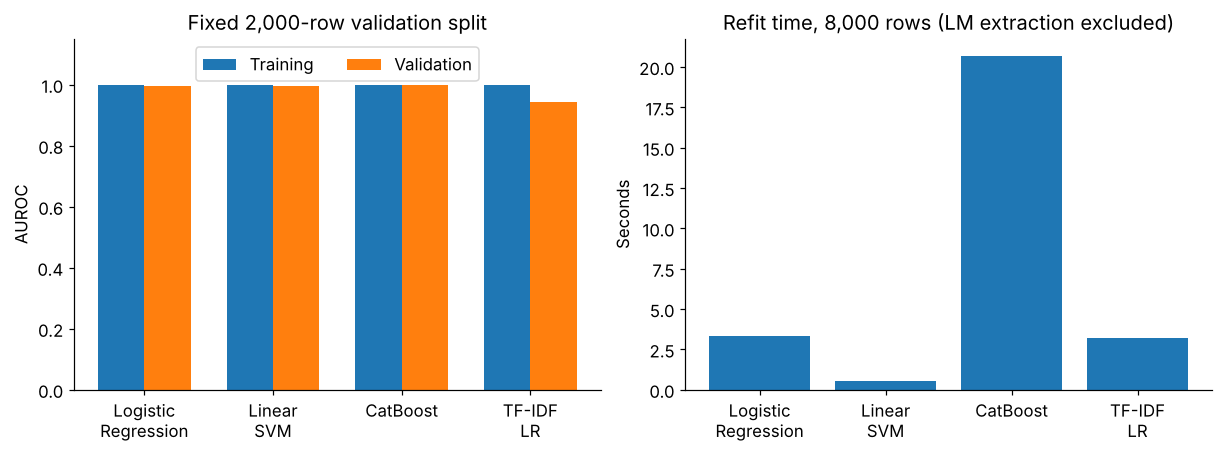

In [ ]:
(fig, axes) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
x = np.arange(len(q1_comparison))
labels = [name.replace(' ', '\n', 1) for name in q1_comparison.Model]
axes[0].bar(x - 0.18, q1_comparison['Train AUROC'], 0.36, label='Training')
axes[0].bar(x + 0.18, q1_comparison['Validation AUROC'], 0.36, label='Validation')
axes[0].set(xticks=x, xticklabels=labels,
    ylabel='AUROC', ylim=(0, 1.15), title='Fixed 2,000-row validation split')
axes[0].legend(ncol=2, loc='upper center')
axes[1].bar(x, q1_comparison['Fit seconds'])
axes[1].set(xticks=x, xticklabels=labels, ylabel='Seconds', title='Refit time, 8,000 rows (LM extraction excluded)')
fig.savefig(RUN_DIR / 'figures/q1_model_comparison.png', dpi=200, bbox_inches='tight')
fig.savefig(RUN_DIR / 'figures/q1_model_comparison.pdf', bbox_inches='tight')
plt.show()


### Q1.3 — Hyperparameters and selection protocol
| Approach | Candidates | Chosen in the reference run |
|---|---|---|
| Logistic Regression | C = 0.01, 0.1, 1, 10, 100 | C = 100 |
| Linear SVM | C = 0.01, 0.1, 1, 10, 100 | C = 100 |
| CatBoost | Depth = 3, 4, 5, 6, 7 | Depth = 6 |
| TF-IDF LR (representation baseline) | C = 0.01, 0.1, 1, 10, 100 | C = 10 (TF-IDF cell output) |

We use stratified five-fold CV inside the 8,000-row training partition, with seed 42 and mean fold AUROC as the selection criterion. Scaling (and, for TF-IDF, the vocabulary and IDF weights) is inside each estimator pipeline, so it is fitted independently in each training fold. Each selected configuration is then refitted on all 8,000 training rows and evaluated once for the displayed comparison on the fixed 2,000-row validation partition. No hidden Kaggle labels are available or used. This CV protocol applies to all four comparison models, including the TF-IDF baseline; the final ensemble's feature choices and weights are inherited from prior development, which included repeated validation and public-leaderboard inspection.


### Q1.4 — Final classifier and selection rationale
The final submitted approach is the fixed weighted ensemble, rather than an automatic switch to whichever comparison model wins a new search. In the reference run, its validation AUROC was **0.999391**, compared with **0.999280** for the comparison CatBoost. This small difference motivated retaining complementary lexical, statistics and vector branches, while acknowledging the extra implementation and training cost. The weights were carried over from earlier development; this reproduction is not an independent, previously untouched model-selection experiment. Stability across multiple splits has not been established.

The development ensemble below is fitted on only the 8,000 training labels. Q4 analyzes these predictions; Q5 compares a fixed control against the added joint branch. Q6 later refits the chosen recipe on all 10,000 labels. The training cells remain expanded in place, without helper functions.


In [ ]:
PHASE = 'development'
phase_fit_ids = FIT_IDS.copy()
phase_predict_ids = np.concatenate([FIT_IDS,VAL_IDS])
phase_y = indexed_train.loc[phase_fit_ids,'label'].to_numpy()
PHASE_DIR = RUN_DIR/'models'/PHASE
PHASE_DIR.mkdir(parents=True,exist_ok=True)
phase_signature = hashlib.sha256(json.dumps({'run_key':RUN_KEY,'ids':phase_fit_ids.tolist(),
    'labels':phase_y.tolist()},sort_keys=True).encode()).hexdigest()
phase_predictions = pd.DataFrame(index=pd.Index(phase_predict_ids,name='id'))
phase_timings = []
print('Fitting complete development system:',len(phase_fit_ids),'labeled rows')


Fitting complete development system: 8000 labeled rows


In [ ]:
# Fit text representations on this phase's labeled rows only.
fit_texts = text_by_id.loc[phase_fit_ids, 'normalized_text'].tolist()
shared_clean = None
sparse_models = {}
for family in SPARSE_FAMILIES:
    cache = PHASE_DIR / f'sparse_{family}.joblib'
    if REUSE_CURRENT_RUN and cache.is_file():
        bundle = joblib.load(cache)
        assert bundle['phase_signature'] == phase_signature
        assert bundle['family'] == family and bundle['run_key'] == RUN_KEY
        fit_seconds = bundle['fit_seconds']
        clean_loss, augmented_loss = bundle['train_log_loss'], bundle['augmented_log_loss']
        print(f'{PHASE}/{family}: restored this run; recorded fit {fit_seconds:.1f}s', flush=True)
    else:
        started = time.perf_counter()
        if family.startswith('clean_'):
            if shared_clean is None:
                word = TfidfVectorizer(**WORD_SETTINGS)
                char = TfidfVectorizer(**CHAR_SETTINGS)
                word_fit = word.fit_transform(fit_texts)
                char_fit = char.fit_transform(fit_texts)
                binary = hstack([.5 * word_fit, char_fit], format='csr')
                binary.data.fill(1.)
                positive = np.asarray(binary[phase_y == 1].sum(axis=0)).ravel().astype(float) + 1.
                negative = np.asarray(binary[phase_y == 0].sum(axis=0)).ravel().astype(float) + 1.
                ratio = np.log(positive / positive.sum() / (negative / negative.sum())).astype(np.float32)
                normalized_text_matrix = normalize(binary.multiply(ratio)).tocsr()
                style_scaler = StandardScaler().fit(style_table.loc[phase_fit_ids].to_numpy())
                scaled_style = style_scaler.transform(style_table.loc[phase_fit_ids].to_numpy())
                shared_clean = {'word':word,'char':char,'ratio':ratio,'scaler':style_scaler,
                    'text_matrix':normalized_text_matrix,'scaled_style':scaled_style,
                    'representation_seconds':time.perf_counter()-started}
                del binary, word_fit, char_fit
            bundle = {k:shared_clean[k] for k in ['word','char','ratio','scaler']}
            if family == 'clean_poly_0.1':
                poly = PolynomialFeatures(degree=2, include_bias=False)
                expanded = poly.fit_transform(np.clip(shared_clean['scaled_style'], -8, 8))
                poly_scaler = StandardScaler().fit(expanded)
                style_matrix = np.clip(poly_scaler.transform(expanded), -8, 8).astype(np.float32) * .1
                bundle.update(poly=poly, poly_scaler=poly_scaler)
            else:
                style_matrix = shared_clean['scaled_style'] * .3
            matrix = hstack([shared_clean['text_matrix'], csr_matrix(style_matrix)], format='csr')
        else:
            # BPE is learned on competition training text, not on validation/test text.
            bpe = Tokenizer(models.BPE(unk_token='[UNK]'))
            bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
            trainer = trainers.BpeTrainer(vocab_size=4000, min_frequency=2,
                special_tokens=['[UNK]'], initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
            bpe.train_from_iterator(fit_texts, trainer=trainer)
            encoded = [' '.join('t'+str(t) for t in item.ids) for item in bpe.encode_batch(fit_texts)]
            vectorizer = TfidfVectorizer(ngram_range=(1,3), min_df=2, max_features=250000,
                lowercase=False, token_pattern=r'(?u)\bt\d+\b', sublinear_tf=True, dtype=np.float32)
            binary = vectorizer.fit_transform(encoded)
            binary.data.fill(1.)
            positive = np.asarray(binary[phase_y == 1].sum(axis=0)).ravel().astype(float) + 1.
            negative = np.asarray(binary[phase_y == 0].sum(axis=0)).ravel().astype(float) + 1.
            ratio = np.log(positive / positive.sum() / (negative / negative.sum())).astype(np.float32)
            matrix = normalize(binary.multiply(ratio)).tocsr()
            bundle = {'tokenizer_json':bpe.to_str(),'vectorizer':vectorizer,'ratio':ratio}
            del binary

        # Mask only nonzero text entries; style columns retain their values.
        corrupted = matrix.copy().tocsr()
        positions = np.flatnonzero(corrupted.indices < len(bundle['ratio']))
        mask_seed = SEED + 1000 * len(phase_fit_ids) + 17 * SPARSE_FAMILIES.index(family)
        rng = np.random.default_rng(mask_seed)
        keep = rng.random(len(positions), dtype=np.float32) >= DROPOUT_RATE
        corrupted.data[positions] *= keep / (1. - DROPOUT_RATE)
        corrupted.eliminate_zeros()
        augmented = vstack([matrix, corrupted], format='csr')
        augmented_y = np.concatenate([phase_y, phase_y])
        sample_weight = np.full(len(augmented_y), .5)
        classifier = LogisticRegression(C=100., solver='liblinear', max_iter=5000,
                                         tol=1e-4, random_state=SEED)
        with threadpool_limits(limits=CPU_THREADS):
            classifier.fit(augmented, augmented_y, sample_weight=sample_weight)
        np.testing.assert_array_equal(classifier.classes_, [0,1])
        clean_loss = log_loss(phase_y, classifier.predict_proba(matrix)[:,1])
        augmented_loss = log_loss(augmented_y, classifier.predict_proba(augmented)[:,1], sample_weight=sample_weight)
        fit_seconds = time.perf_counter() - started
        bundle.update(classifier=classifier, family=family, phase_signature=phase_signature,
            run_key=RUN_KEY, fit_seconds=fit_seconds, mask_seed=mask_seed,
            training_rows=len(phase_fit_ids), dropout=DROPOUT_RATE,
            train_log_loss=float(clean_loss), augmented_log_loss=float(augmented_loss))
        temporary = cache.with_suffix('.tmp')
        joblib.dump(bundle, temporary, compress=3)
        temporary.replace(cache)
        # Use the persisted object for inference, so serialization is exercised.
        bundle = joblib.load(cache)
        del matrix, corrupted, augmented, augmented_y, sample_weight, positions, keep
        print(f'{PHASE}/{family}: trained in {fit_seconds:.1f}s; train log loss {clean_loss:.5f}', flush=True)

    # Transform and predict in batches to limit local memory use.
    predicted = []
    for begin in range(0, len(phase_predict_ids), 256):
        batch_ids = phase_predict_ids[begin:begin+256]
        texts = text_by_id.loc[batch_ids, 'normalized_text'].tolist()
        if family == 'bpe_nb':
            bpe = Tokenizer.from_str(bundle['tokenizer_json'])
            encoded = [' '.join('t'+str(t) for t in item.ids) for item in bpe.encode_batch(texts)]
            matrix = bundle['vectorizer'].transform(encoded)
        else:
            matrix = hstack([.5*bundle['word'].transform(texts),bundle['char'].transform(texts)],format='csr')
        matrix = matrix.copy()
        matrix.data.fill(1.)
        matrix = normalize(matrix.multiply(bundle['ratio'])).tocsr()
        if family != 'bpe_nb':
            raw_style = style_table.loc[batch_ids].to_numpy()
            if family == 'clean_poly_0.1':
                scaled = np.clip(bundle['scaler'].transform(raw_style), -8, 8)
                expanded = bundle['poly'].transform(scaled)
                style_matrix = np.clip(bundle['poly_scaler'].transform(expanded), -8, 8).astype(np.float32) * .1
            else:
                style_matrix = bundle['scaler'].transform(raw_style) * .3
            matrix = hstack([matrix,csr_matrix(style_matrix)],format='csr')
        predicted.append(bundle['classifier'].predict_proba(matrix)[:,1])
    phase_predictions[family] = np.concatenate(predicted)
    phase_timings.append({'Branch':family,'Fit seconds':fit_seconds,
        'Cost scope':'representation construction and classifier fit; shared word/char setup counted once',
        'Train log loss':clean_loss,'Augmented log loss':augmented_loss})
    sparse_models[family] = str(cache)
    del bundle, matrix
    gc.collect()
shared_clean = None
phase_predictions['sparse'] = sum(SPARSE_WEIGHTS[name]*phase_predictions[name] for name in SPARSE_FAMILIES)
assert np.isfinite(phase_predictions['sparse']).all()
display(pd.DataFrame(phase_timings))


development/clean_nbstyle_0.3: trained in 95.0s; train log loss 0.01087
development/clean_poly_0.1: trained in 79.9s; train log loss 0.00856
development/bpe_nb: trained in 31.7s; train log loss 0.01076


,Branch,Fit seconds,Cost scope,Train log loss,Augmented log loss
0,clean_nbstyle_0.3,94.993161,representation construction and classifier fit...,0.010872,0.010217
1,clean_poly_0.1,79.919871,representation construction and classifier fit...,0.008564,0.008089
2,bpe_nb,31.667361,representation construction and classifier fit...,0.010756,0.010404


In [ ]:
# Fit each dense branch; data-dependent transformations are inside the fitted bundle.
for branch, spec in DENSE_RECIPE.items():
    cache = PHASE_DIR / f'{branch}.joblib'
    if spec['view'] == 'embedding':
        fit_x = embeddings.loc[phase_fit_ids].to_numpy()
        predict_x = embeddings.loc[phase_predict_ids].to_numpy()
    elif spec['view'] == 'joint_embedding':
        fit_vectors = embeddings.loc[phase_fit_ids].to_numpy()
        predict_vectors = embeddings.loc[phase_predict_ids].to_numpy()
        fit_norms = np.linalg.norm(fit_vectors, axis=1, keepdims=True)
        predict_norms = np.linalg.norm(predict_vectors, axis=1, keepdims=True)
        assert (fit_norms > 0).all() and (predict_norms > 0).all()
        fit_vectors = (fit_vectors / fit_norms).astype(np.float32)
        predict_vectors = (predict_vectors / predict_norms).astype(np.float32)
    else:
        fit_x = stats.loc[phase_fit_ids, VIEW_COLUMNS[spec['view']]].to_numpy()
        predict_x = stats.loc[phase_predict_ids, VIEW_COLUMNS[spec['view']]].to_numpy()

    if REUSE_CURRENT_RUN and cache.is_file():
        saved = joblib.load(cache)
        assert saved['phase_signature'] == phase_signature and saved['spec'] == spec
        assert saved['run_key'] == RUN_KEY
        model = saved['model']
        fit_seconds = saved['fit_seconds']
        print(f'{PHASE}/{branch}: restored this run; recorded fit {fit_seconds:.1f}s', flush=True)
    else:
        started = time.perf_counter()
        fitted_pca = None
        if spec['kind'] == 'polynomial_lr':
            model = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2,include_bias=False),
                StandardScaler(), LogisticRegression(C=spec['C'],solver='lbfgs',
                    max_iter=spec['max_iter'],tol=spec['tol'],random_state=SEED))
        elif spec['kind'] == 'embedding_lr':
            model = make_pipeline(Normalizer(),StandardScaler(),
                LogisticRegression(C=spec['C'],solver='lbfgs',max_iter=spec['max_iter'],
                    tol=spec['tol'],random_state=SEED))
        else:
            if spec['kind'] == 'embedding_tree':
                fitted_pca = PCA(n_components=32,svd_solver='randomized',random_state=SEED)
                with threadpool_limits(limits=CPU_THREADS):
                    fitted_pca.fit(fit_vectors)
                fit_pc = fitted_pca.transform(fit_vectors)[:, :16]
                fit_x = np.hstack([stats.loc[phase_fit_ids].to_numpy(),fit_pc])
            model = CatBoostClassifier(depth=spec['depth'],**TREE_SETTINGS)
        with threadpool_limits(limits=CPU_THREADS):
            model.fit(fit_x,phase_y)
        fit_seconds = time.perf_counter()-started
        np.testing.assert_array_equal(model.classes_,[0,1])
        train_loss = float(log_loss(phase_y,model.predict_proba(fit_x)[:,1]))
        saved = {'model':model,'pca':fitted_pca,'spec':spec,'run_key':RUN_KEY,
            'phase_signature':phase_signature,'training_rows':len(phase_fit_ids),
            'fit_seconds':fit_seconds,'train_log_loss':train_loss}
        temporary = cache.with_suffix('.tmp')
        joblib.dump(saved,temporary,compress=3)
        temporary.replace(cache)
        restored = joblib.load(cache)
        np.testing.assert_allclose(restored['model'].predict_proba(fit_x[:16]),
                                   model.predict_proba(fit_x[:16]),rtol=0,atol=1e-12)
        saved,model = restored,restored['model']
        print(f'{PHASE}/{branch}: trained in {fit_seconds:.1f}s; train log loss {train_loss:.5f}',flush=True)
    if spec['kind'] == 'embedding_tree':
        predict_pc = saved['pca'].transform(predict_vectors)[:, :16]
        predict_x = np.hstack([stats.loc[phase_predict_ids].to_numpy(),predict_pc])
    p = model.predict_proba(predict_x)[:,1]
    assert p.shape==(len(phase_predict_ids),) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    phase_predictions[branch] = p
    phase_timings.append({'Branch':branch,'Fit seconds':fit_seconds,
        'Cost scope':'classifier and fitted transformations; frozen feature extraction excluded',
        'Train log loss':saved['train_log_loss'],'Augmented log loss':np.nan})
display(pd.DataFrame(phase_timings))


development/norm_lr: trained in 7.6s; train log loss 0.19643
development/embedding_lr: trained in 2.3s; train log loss 0.16271
development/raw_lr: trained in 2.8s; train log loss 0.12612
development/joint_lr: trained in 4.4s; train log loss 0.11114
development/structure_tree: trained in 14.6s; train log loss 0.02083
development/dual_lm_tree: trained in 5.3s; train log loss 0.06302
development/all_features_tree: trained in 20.0s; train log loss 0.01574
development/embedding_statistics_tree: trained in 22.3s; train log loss 0.01326


,Branch,Fit seconds,Cost scope,Train log loss,Augmented log loss
0,clean_nbstyle_0.3,94.993161,representation construction and classifier fit...,0.010872,0.010217
1,clean_poly_0.1,79.919871,representation construction and classifier fit...,0.008564,0.008089
2,bpe_nb,31.667361,representation construction and classifier fit...,0.010756,0.010404
3,norm_lr,7.620737,classifier and fitted transformations; frozen ...,0.196434,NaN
4,embedding_lr,2.306544,classifier and fitted transformations; frozen ...,0.162712,NaN
5,raw_lr,2.785384,classifier and fitted transformations; frozen ...,0.126117,NaN
6,joint_lr,4.360783,classifier and fitted transformations; frozen ...,0.111139,NaN
7,structure_tree,14.639327,classifier and fitted transformations; frozen ...,0.020835,NaN
8,dual_lm_tree,5.306116,classifier and fitted transformations; frozen ...,0.063018,NaN
9,all_features_tree,20.030891,classifier and fitted transformations; frozen ...,0.015743,NaN


In [ ]:
# Expand the same nested recipe used by the historical system.
p_base = .6*phase_predictions['sparse'] + .4*phase_predictions.norm_lr
phase_predictions['legacy_lr'] = (
    .9*(.7*(.8*p_base + .2*phase_predictions.embedding_lr)
         + .3*phase_predictions.raw_lr) + .1*phase_predictions.joint_lr)
phase_predictions['control'] = (
    .16*phase_predictions.legacy_lr + .24*phase_predictions.structure_tree
    + .10*phase_predictions.dual_lm_tree + .50*phase_predictions.all_features_tree)
phase_predictions['probability'] = sum(
    FINAL_WEIGHTS[name]*phase_predictions[name] for name in FINAL_WEIGHTS)
np.testing.assert_allclose(phase_predictions.probability,
    .5*phase_predictions.control + .5*phase_predictions.embedding_statistics_tree,atol=1e-12,rtol=0)
assert np.isfinite(phase_predictions.to_numpy()).all()
assert ((phase_predictions>=0)&(phase_predictions<=1)).all().all()
print(PHASE,'fusion complete:',phase_predictions.shape)

development_predictions = phase_predictions.copy()
development_timings = pd.DataFrame(phase_timings)
development_predictions['label'] = indexed_train.loc[phase_predict_ids,'label']
development_predictions['split'] = ['train']*len(FIT_IDS)+['validation']*len(VAL_IDS)
development_predictions.to_csv(RUN_DIR/'tables/development_predictions.csv')
development_timings.to_csv(RUN_DIR/'tables/development_training_times.csv',index=False)
display(development_timings)
print('Development ensemble is ready for Q4 and Q5.')


development fusion complete: (10000, 15)


,Branch,Fit seconds,Cost scope,Train log loss,Augmented log loss
0,clean_nbstyle_0.3,94.993161,representation construction and classifier fit...,0.010872,0.010217
1,clean_poly_0.1,79.919871,representation construction and classifier fit...,0.008564,0.008089
2,bpe_nb,31.667361,representation construction and classifier fit...,0.010756,0.010404
3,norm_lr,7.620737,classifier and fitted transformations; frozen ...,0.196434,NaN
4,embedding_lr,2.306544,classifier and fitted transformations; frozen ...,0.162712,NaN
5,raw_lr,2.785384,classifier and fitted transformations; frozen ...,0.126117,NaN
6,joint_lr,4.360783,classifier and fitted transformations; frozen ...,0.111139,NaN
7,structure_tree,14.639327,classifier and fitted transformations; frozen ...,0.020835,NaN
8,dual_lm_tree,5.306116,classifier and fitted transformations; frozen ...,0.063018,NaN
9,all_features_tree,20.030891,classifier and fitted transformations; frozen ...,0.015743,NaN


Development ensemble is ready for Q4 and Q5.


Fitting cost in the saved run, from the branch timing table above: **285.90 seconds** for the full 8,000-row ensemble. Shared feature extraction across all 16,000 documents took **32.98 minutes** (1,978.6 s). These scopes exclude hyperparameter search, prediction, serialization and downloads; they must not be described as total end-to-end runtime.


## Q2 — Effect of labeled training size
### Q2.1 — Fixed configuration and nested training subsets
Use the CV-selected comparison CatBoost configuration for 500, 1,000, 2,000, 5,000 and 8,000 class-balanced examples sampled from the fixed training partition. Its parameters and the 2,000-row validation set remain fixed. Frozen per-document features are reused. The assignment asks for one model configuration; this experiment is not presented as the learning curve of the entire ensemble.


{'Training rows': 500, 'Train AUROC': np.float64(1.0), 'Validation AUROC': np.float64(0.9972909999999999), 'Fit seconds': 15.716566711000269}
{'Training rows': 1000, 'Train AUROC': np.float64(1.0), 'Validation AUROC': np.float64(0.9976849999999999), 'Fit seconds': 16.67679191299976}
{'Training rows': 2000, 'Train AUROC': np.float64(1.0), 'Validation AUROC': np.float64(0.997922), 'Fit seconds': 17.804032947999985}
{'Training rows': 5000, 'Train AUROC': np.float64(1.0), 'Validation AUROC': np.float64(0.999071), 'Fit seconds': 17.966366129000562}
{'Training rows': 8000, 'Train AUROC': np.float64(0.9999933750000001), 'Validation AUROC': np.float64(0.999312), 'Fit seconds': 18.806418852000206}


,Training rows,Train AUROC,Validation AUROC,Fit seconds
0,500,1.000000,0.997291,15.716567
1,1000,1.000000,0.997685,16.676792
2,2000,1.000000,0.997922,17.804033
3,5000,1.000000,0.999071,17.966366
4,8000,0.999993,0.999312,18.806419


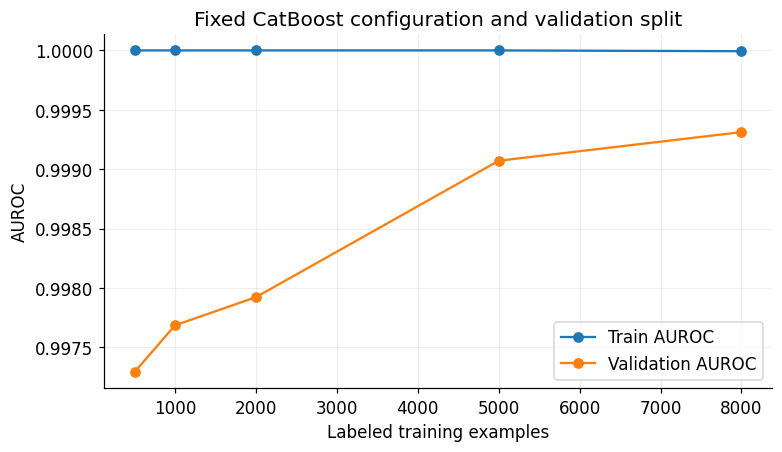

In [ ]:
q2_path = RUN_DIR / 'tables/q2_learning_curve.csv'
if REUSE_CURRENT_RUN and q2_path.is_file():
    q2_curve = pd.read_csv(q2_path)
    print('Restored completed learning-curve experiment.')
else:
    rng = np.random.default_rng(SEED)
    class_order = {label: rng.permutation(np.flatnonzero(y_fit == label)) for label in [0, 1]}
    (rows, selected_ids) = ([], [])
    for size in TRAINING_SIZES:
        indices = np.concatenate([class_order[0][:size // 2], class_order[1][:size // 2]])
        indices = np.random.default_rng(SEED).permutation(indices)
        started = time.perf_counter()
        with threadpool_limits(limits=CPU_THREADS):
            model = clone(q1_models['CatBoost']).fit(X_fit.iloc[indices], y_fit[indices])
        seconds = time.perf_counter() - started
        rows.append({'Training rows': size, 'Train AUROC': roc_auc_score(y_fit[indices],
                    model.predict_proba(X_fit.iloc[indices])[:, 1] if hasattr(model,
                    'predict_proba') else model.decision_function(X_fit.iloc[indices])),
                'Validation AUROC': roc_auc_score(y_val, model.predict_proba(X_val)[:,
                    1] if hasattr(model, 'predict_proba') else model.decision_function(X_val)),
                'Fit seconds': seconds})
        selected_ids.extend(({'training_size': size, 'id': int(i)} for i in FIT_IDS[indices]))
        print(rows[-1], flush=True)
    q2_curve = pd.DataFrame(rows)
    pd.DataFrame(selected_ids).to_csv(RUN_DIR / 'tables/q2_subset_ids.csv', index=False)
q2_curve.to_csv(RUN_DIR / 'tables' / 'q2_learning_curve.csv', index=False)
display(q2_curve)
(fig, ax) = plt.subplots(figsize=(7, 4), constrained_layout=True)
for col in ['Train AUROC', 'Validation AUROC']:
    ax.plot(q2_curve['Training rows'], q2_curve[col], 'o-', label=col)
ax.set(xlabel='Labeled training examples', ylabel='AUROC', title='Fixed CatBoost configuration and validation split')
ax.legend()
ax.grid(alpha=0.2)
fig.savefig(RUN_DIR / 'figures/q2_learning_curve.png', dpi=200, bbox_inches='tight')
fig.savefig(RUN_DIR / 'figures/q2_learning_curve.pdf', bbox_inches='tight')
plt.show()


### Q2.2 — Learning-curve figure
The figure above plots training and validation AUROC against labeled sample size. It is saved as `figures/q2_learning_curve.png` and `.pdf` under the current run directory.

### Q2.3 — Interpretation of the observed curve
Training AUROC is essentially one at every sample size, while validation AUROC rises from 0.997291 with 500 examples to 0.999312 with 8,000. The training-validation gap therefore narrows as labeled data increases. This is consistent with the model fitting small samples very easily and benefiting from more examples for generalization; there is no strong evidence of underfitting in this experiment. The last increase, from 5,000 to 8,000 rows, is smaller than the increase from 2,000 to 5,000. However, the curve follows one nested sampling sequence and one validation split, so diminishing returns and uncertainty are not established statistically. The 8,000-row ordering here differs from the comparison refit; small numerical differences between their scores should not be treated as a new method.


## Q3 — Learning from unlabeled data
### Q3.1 — Method and leakage prevention
The comparison CatBoost fitted on 8,000 true labels acts as teacher. Normalize texts for duplicate checking, excluding duplicates against all labeled texts and repeated unlabeled texts. Assign pseudo-labels only where P(AI) ≤ 0.05 or ≥ 0.95. Refit an otherwise identical student using weight 1 for true labels and 0.25 for pseudo-labels. The teacher, confidence filter and student do not access validation labels during fitting. Validation text is used only for duplicate exclusion, not for learning representations or setting pseudo-labels. Evaluate teacher and student on the same held-out rows. This experiment does not automatically alter the locked final submission recipe.

### Q3.2 — Supervised versus semi-supervised results


In [ ]:
q3_cache = RUN_DIR/'models/q3_student.joblib'
if REUSE_CURRENT_RUN and q3_cache.is_file():
    saved = joblib.load(q3_cache)
    assert saved['run_key']==RUN_KEY
    q3_comparison = pd.DataFrame(saved['rows'])
    print('Restored the completed pseudo-label experiment for this run.')
else:
    teacher = q1_models['CatBoost']
    u_prob = teacher.predict_proba(X_unlabeled)[:,1]
    assert np.isfinite(u_prob).all() and ((u_prob>=0)&(u_prob<=1)).all()
    labeled_texts = set(text_by_id.loc[train.id,'normalized_text'])
    u_clean = text_by_id.loc[unlabeled.id,'normalized_text'].reset_index(drop=True)
    duplicate = u_clean.isin(labeled_texts) | u_clean.duplicated(keep='first')
    selected = ((u_prob<=PSEUDO_LOW)|(u_prob>=PSEUDO_HIGH)) & ~duplicate.to_numpy()
    pseudo_labels = (u_prob>=.5).astype(int)
    audit = unlabeled[['id']].assign(probability=u_prob,pseudo_label=pseudo_labels,
        duplicate_excluded=duplicate.to_numpy(),selected=selected)
    audit.to_csv(RUN_DIR/'tables/q3_pseudo_label_audit.csv',index=False)
    teacher_p = teacher.predict_proba(X_val)[:,1]
    if selected.any():
        augmented_x = pd.concat([X_fit,X_unlabeled.iloc[np.flatnonzero(selected)]],ignore_index=True)
        augmented_y = np.concatenate([y_fit,pseudo_labels[selected]])
        weights = np.concatenate([np.ones(len(y_fit)),np.full(selected.sum(),PSEUDO_WEIGHT)])
        started = time.perf_counter()
        with threadpool_limits(limits=CPU_THREADS):
            student = clone(teacher).fit(augmented_x,augmented_y,sample_weight=weights)
        seconds = time.perf_counter()-started
        student_p = student.predict_proba(X_val)[:,1]
    else:
        student,seconds,student_p = None,0.,teacher_p.copy()
        print('No rows passed the fixed rule. No student was fitted; unchanged teacher predictions are reported.')
    rows = [
        {'Method':'Supervised teacher','Validation AUROC':roc_auc_score(y_val,teacher_p),
         'Pseudo-label rows':0,'Additional fit seconds':0.},
        {'Method':'Pseudo-label student' if student is not None else 'No eligible rows; unchanged teacher',
         'Validation AUROC':roc_auc_score(y_val,student_p),'Pseudo-label rows':int(selected.sum()),
         'Additional fit seconds':seconds}]
    joblib.dump({'run_key':RUN_KEY,'model':student,'rows':rows},q3_cache)
    pd.DataFrame({'id':VAL_IDS,'label':y_val,'teacher':teacher_p,'student_or_unchanged':student_p}).to_csv(
        RUN_DIR/'tables/q3_validation_predictions.csv',index=False)
    q3_comparison = pd.DataFrame(rows)
q3_comparison.to_csv(RUN_DIR/'tables/q3_comparison.csv',index=False)
display(q3_comparison)
audit = pd.read_csv(RUN_DIR/'tables/q3_pseudo_label_audit.csv')
print('Selected pseudo-label counts:',audit.loc[audit.selected,'pseudo_label'].value_counts().to_dict())
print('Validation AUROC change:',q3_comparison['Validation AUROC'].iloc[1]-q3_comparison['Validation AUROC'].iloc[0])


,Method,Validation AUROC,Pseudo-label rows,Additional fit seconds
0,Supervised teacher,0.999280,0,0.000000
1,Pseudo-label student,0.999266,2747,22.000949


Selected pseudo-label counts: {0: 1400, 1: 1347}
Validation AUROC change: -1.4000000000069512e-05


### Q3.3 — What did the unlabeled examples add?
The teacher selected **2,747** examples: 1,400 pseudo-human and 1,347 pseudo-AI. Validation AUROC changed from **0.999280** to **0.999266**, a decrease of **0.000014**. We therefore do not claim an improvement from this experiment. Teacher confidence does not guarantee correct pseudo-labels, and selected examples may largely repeat distinctions the teacher already recognizes. Either noisy pseudo-labels or limited new information could explain the result, but this experiment does not isolate those causes. The change is very small and is based on one split; its sign is not evidence of a stable deterioration. The final recipe continues to use only true training labels. A follow-up could compare thresholds or weights using training-only cross-validation before another held-out assessment.


## Q4 — Generalization and error analysis
### Q4.1 — Training versus validation for the final selected model
Use the complete 8,000-row ensemble from Q1.4. These validation predictions are not produced by the later 10,000-row models. The reference AUROCs are **0.999996** on training and **0.999391** on validation, a gap of about **0.000605**. Near-perfect training fit and a small held-out gap are consistent with strong performance on this split, but do not establish robustness to new domains, generators or adversarial edits. Repeated development on the same validation set also limits how independent this estimate is. The team-reported public AUROC, 0.98819, is lower, but different evaluation samples and their unknown composition prevent attributing that difference to one particular cause.


In [ ]:
q4_metrics = pd.DataFrame([{'Split':split,'Rows':len(part),
    'AUROC':roc_auc_score(part.label,part.probability),
    'Log loss':log_loss(part.label,part.probability)}
    for split,part in development_predictions.groupby('split',sort=False)])
q4_metrics.to_csv(RUN_DIR/'tables/q4_final_model_metrics.csv',index=False)
display(q4_metrics)
final_val = development_predictions.loc[VAL_IDS].copy()
final_val['text'] = indexed_train.loc[VAL_IDS,'text']
final_val = final_val.reset_index()
print('Training–validation AUROC gap:',q4_metrics.AUROC.iloc[0]-q4_metrics.AUROC.iloc[1])


,Split,Rows,AUROC,Log loss
0,train,8000,0.999996,0.021326
1,validation,2000,0.999391,0.035703


Training–validation AUROC gap: 0.0006051875000000484


### Q4.2 — Performance across observable length groups
Define groups using whitespace-word counts: **≤150**, **151–250**, and **>250**. These are observable properties and do not require hidden source or generator labels. The reference counts are 413, 1,056 and 531, with AUROCs 0.999426, 0.999752 and 0.998896. The longest group has the lowest observed AUROC, although all are high. Length can change the quantity of evidence and how averaging compresses local variation; these are hypotheses, not demonstrated causes. The groups also differ in class balance and possibly content. No uncertainty intervals are computed, so the numerical ordering should not be presented as a statistically established length effect.


,Length bin,Rows,Human,AI,Validation AUROC
0,≤150,413,156,257,0.999426
1,151–250,1056,619,437,0.999752
2,>250,531,225,306,0.998896


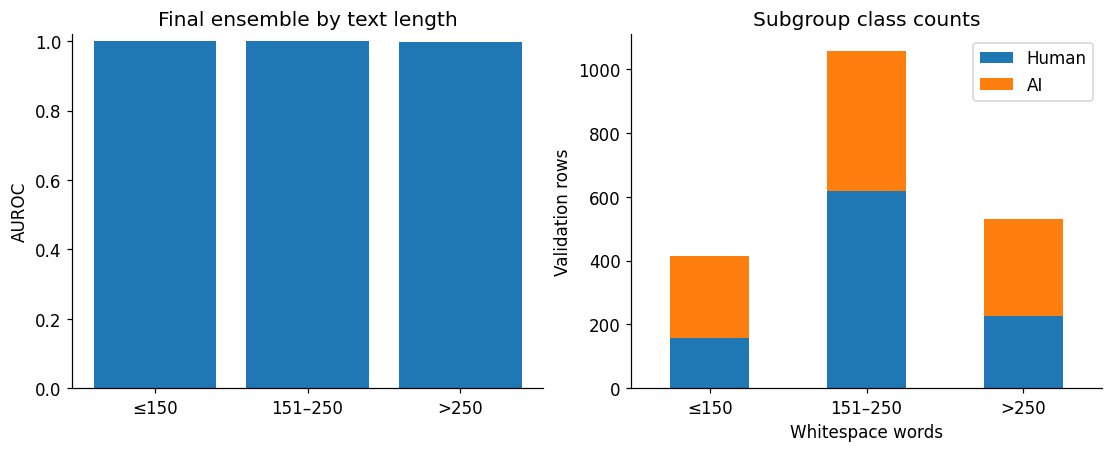

In [ ]:
final_val['words'] = final_val.text.str.split().str.len()
final_val['length_bin'] = pd.cut(final_val.words, [0, 150, 250, np.inf], labels=['≤150', '151–250', '>250'])
rows = []
for (name, group) in final_val.groupby('length_bin', observed=True):
    rows.append({'Length bin': str(name), 'Rows': len(group),
            'Human': int(group.label.eq(0).sum()), 'AI': int(group.label.eq(1).sum()),
            'Validation AUROC': roc_auc_score(group.label,
                group.probability) if group.label.nunique() == 2 else np.nan})
q4_groups = pd.DataFrame(rows)
q4_groups.to_csv(RUN_DIR / 'tables' / 'q4_length_groups.csv', index=False)
display(q4_groups)
(fig, axes) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].bar(q4_groups['Length bin'], q4_groups['Validation AUROC'])
axes[0].set(ylabel='AUROC', ylim=(0, 1.02), title='Final ensemble by text length')
q4_groups.set_index('Length bin')[['Human', 'AI']].plot.bar(ax=axes[1], stacked=True, rot=0)
axes[1].set(ylabel='Validation rows', xlabel='Whitespace words', title='Subgroup class counts')
fig.savefig(RUN_DIR / 'figures/q4_length_subgroups.png', dpi=200, bbox_inches='tight')
fig.savefig(RUN_DIR / 'figures/q4_length_subgroups.pdf', bbox_inches='tight')
plt.show()


### Q4.3 — Five real false positives and five real false negatives
A false positive is labeled human but predicted AI; a false negative is labeled AI but predicted human. At threshold **0.5**, the reference run has 4 FP and 10 FN. At the explicitly declared review threshold **0.48**, it has 5 FP and 9 FN, from which seed 42 samples five of each. The threshold was historically selected for case coverage, not independently optimized for accuracy. It does not change probability submissions or AUROC.

The table attaches observed text characteristics and failure hypotheses only to actual selected IDs whose texts match the reference text hashes. The hypotheses began as AI-assisted drafts; the team then read each full text and reviewed them, and the report's Q4.3 table gives the reviewed versions. They are not feature-attribution results or claims about hidden sources. The `review_status` column in the saved output was written before that review. Full passages are not printed here.


In [ ]:
threshold_rows = []
for threshold in [.5,.48]:
    tn,fp,fn,tp = confusion_matrix(final_val.label,final_val.probability>=threshold,labels=[0,1]).ravel()
    threshold_rows.append({'Threshold':threshold,'TN':tn,'FP':fp,'FN':fn,'TP':tp})
counts = pd.DataFrame(threshold_rows)
counts.to_csv(RUN_DIR/'tables/q4_threshold_counts.csv',index=False)
display(counts)
all_cases = final_val.copy()
all_cases['predicted_label'] = (all_cases.probability>=.48).astype(int)
all_cases['error_type'] = np.select([
    (all_cases.label==0)&(all_cases.predicted_label==1),
    (all_cases.label==1)&(all_cases.predicted_label==0)],['FP','FN'],default='Correct')
all_cases.to_csv(RUN_DIR/'tables/q4_all_validation_cases.csv',index=False)
selected_cases = []
for kind in ['FP','FN']:
    pool = all_cases[all_cases.error_type.eq(kind)]
    if len(pool)<5:
        print(f'Only {len(pool)} actual {kind} at threshold 0.48; the report needs an explicit explanation.')
    selected_cases.append(pool.sample(n=min(5,len(pool)),random_state=SEED))
sampled_errors = pd.concat(selected_cases).sort_values(['error_type','id'])
sampled_errors['decision_threshold'] = .48
sampled_errors['excerpt'] = sampled_errors.text.str.slice(0,300)
sampled_errors['reviewed_failure_hypothesis'] = ''
review_path = RUN_DIR/'tables/q4_error_review.csv'
if review_path.is_file():
    prior_review = pd.read_csv(review_path).set_index('id')
    sampled_errors['reviewed_failure_hypothesis'] = sampled_errors.id.map(
        prior_review.reviewed_failure_hypothesis).fillna('')
sampled_errors.to_csv(review_path,index=False)
display(sampled_errors[['id','error_type','label','probability','reviewed_failure_hypothesis']])
print('Review the complete text and add your hypotheses:',review_path)

# AI-assisted drafts for the actual reference-run cases; team review remains explicit.
CASE_NOTES = {1362: {'text_sha256': 'f5ad3bdb0ba0d1f93b93c3da0fb1ddc17e2b989d441af1d71bb332fb03a8517b', 'observation': 'Encoding artifacts, technical names, dates and numbered references.', 'hypothesis': 'Web-like formatting and uncommon terms may resemble human-source material even though the supplied label is AI.'}, 5010: {'text_sha256': '40b1b56f59898c82b543aa62ce2ce2e08ad76ca6bb77c8ea7ec07e6638b2834a', 'observation': 'Dense biography with many names, credits, dates and inline reference numbers.', 'hypothesis': 'Entity-heavy, reference-like prose may weaken probability-based authorship signals; no factual verification was performed.'}, 5498: {'text_sha256': '3624087e04c246e91b2bd43486d838497f1a3ec109eed5df6967990f2461f0dd', 'observation': 'Ingredient list followed by detailed, conventional cooking instructions.', 'hypothesis': 'Human and AI recipes share a constrained structure and vocabulary, making these features less discriminative.'}, 9070: {'text_sha256': 'e9bab1b23551af524477a336ca7a863fa1d6b5e0fb0ca00334a1093ac31e76f3', 'observation': 'Multiple article fragments mixed with category/tag lists and truncation markers.', 'hypothesis': 'Fragmented web formatting may resemble human-source extraction artifacts; the true generating source is unknown.'}, 9298: {'text_sha256': '3abc988502912e1b90d4c576d917f662766379474a0d1cac199bda3c2dbc7b76', 'observation': 'Biography followed by incomplete lines and repeated search-like phrases.', 'hypothesis': 'Noisy trailing text may resemble human web material and obscure the authorship signal in the main paragraph.'}, 1573: {'text_sha256': '33e51f3988396af25d8dda1c4f7b756dfd407967ad8cd91b3444ecdf72945904', 'observation': 'Formal chronological prose; probability 0.484841 lies between the two reported thresholds.', 'hypothesis': 'This FP is threshold-sensitive: it is classified correctly at 0.5 and incorrectly at the declared review threshold 0.48.'}, 3326: {'text_sha256': '06bb13a68faae09aaf34289d72fa12335077007fb74851251ce0799007f886b8', 'observation': 'Polished positive film review with conventional praise and transitions.', 'hypothesis': 'Formulaic review language may overlap with AI-written examples; the wording alone cannot establish authorship.'}, 3571: {'text_sha256': 'fdb99326c5a044ebaa056dd526b244c57f262287dc933153fd561597bb0e44cd', 'observation': 'Short first-person film review with a typo, a list of criticisms and a concluding opinion.', 'hypothesis': 'Limited text and familiar review phrasing may make the score uncertain; the probability is close to 0.5.'}, 5482: {'text_sha256': '868394d60f75448c69b8aa2a1f8df6e9c52b5bd785a7e8fad11603fb0d6f6109', 'observation': 'Repeated first-person relationship concerns and repeated sentence openings.', 'hypothesis': 'Repetition may trigger features associated with AI writing despite being natural in informal human expression.'}, 8528: {'text_sha256': 'ba6caf1066503e59dd2fd8bb1d3c0637836722448f5cdc433fd162eaa2ce570b', 'observation': 'Chronological biography with dates, names, quotations and a paragraph break.', 'hypothesis': 'Encyclopedic organization is shared across authorship classes; feature attribution would be needed to identify the actual driver.'}}
sampled_errors['observed_characteristics'] = ''
sampled_errors['draft_failure_hypothesis'] = ''
for row_index, case in sampled_errors.iterrows():
    note = CASE_NOTES.get(int(case['id']))
    if note and hashlib.sha256(case['text'].encode()).hexdigest() == note['text_sha256']:
        sampled_errors.loc[row_index,'observed_characteristics'] = note['observation']
        sampled_errors.loc[row_index,'draft_failure_hypothesis'] = note['hypothesis']
sampled_errors['review_status'] = np.where(
    sampled_errors['reviewed_failure_hypothesis'].fillna('').str.strip().ne(''),
    'Team review entered; verify before submission', 'AI-assisted draft; team review pending')
sampled_errors.to_csv(review_path,index=False)
display(sampled_errors[['id','error_type','probability','observed_characteristics',
    'draft_failure_hypothesis','review_status']])
print('Notes attach only to matching real texts. New sampled IDs require new analysis.')


,Threshold,TN,FP,FN,TP
0,0.50,996,4,10,990
1,0.48,995,5,9,991


,id,error_type,label,probability,reviewed_failure_hypothesis
1215,1362,FN,1,0.049868,
1649,5010,FN,1,0.015121,
259,5498,FN,1,0.423625,
1639,9070,FN,1,0.315406,
476,9298,FN,1,0.166785,
762,1573,FP,0,0.484841,
835,3326,FP,0,0.784701,
1144,3571,FP,0,0.509912,
1602,5482,FP,0,0.547451,
194,8528,FP,0,0.549585,


Review the complete text and add your hypotheses: /content/drive/MyDrive/human_or_ai/outputs/full_colab_training/runs/3bd0a8a7c0bd60ce/tables/q4_error_review.csv


,id,error_type,probability,observed_characteristics,draft_failure_hypothesis,review_status
1215,1362,FN,0.049868,"Encoding artifacts, technical names, dates and...",Web-like formatting and uncommon terms may res...,AI-assisted draft; team review pending
1649,5010,FN,0.015121,"Dense biography with many names, credits, date...","Entity-heavy, reference-like prose may weaken ...",AI-assisted draft; team review pending
259,5498,FN,0.423625,"Ingredient list followed by detailed, conventi...",Human and AI recipes share a constrained struc...,AI-assisted draft; team review pending
1639,9070,FN,0.315406,Multiple article fragments mixed with category...,Fragmented web formatting may resemble human-s...,AI-assisted draft; team review pending
476,9298,FN,0.166785,Biography followed by incomplete lines and rep...,Noisy trailing text may resemble human web mat...,AI-assisted draft; team review pending
762,1573,FP,0.484841,Formal chronological prose; probability 0.4848...,This FP is threshold-sensitive: it is classifi...,AI-assisted draft; team review pending
835,3326,FP,0.784701,Polished positive film review with conventiona...,Formulaic review language may overlap with AI-...,AI-assisted draft; team review pending
1144,3571,FP,0.509912,"Short first-person film review with a typo, a ...",Limited text and familiar review phrasing may ...,AI-assisted draft; team review pending
1602,5482,FP,0.547451,Repeated first-person relationship concerns an...,Repetition may trigger features associated wit...,AI-assisted draft; team review pending
194,8528,FP,0.549585,"Chronological biography with dates, names, quo...",Encyclopedic organization is shared across aut...,AI-assisted draft; team review pending


Notes attach only to matching real texts. New sampled IDs require new analysis.


### Q4.4 — Recurring patterns and a proposed response
**Observed in these ten selected cases:** several AI-labeled false negatives use biographies, references, truncated fragments or web-like trailing material. The recipe false negative uses conventional ingredient and instruction structure. Human-labeled false positives include formal biographies, polished review language and repeated first-person phrasing. One false positive, ID 1573, appears only after changing the review threshold from 0.5 to 0.48. These examples demonstrate overlap in observable style across the two classes; they do not identify the hidden generators or prove which feature caused a decision.

**Hypothesis and untested follow-up:** reliance on web formatting or formulaic prose may reduce robustness. One targeted experiment would train with controlled whitespace/format perturbations and compare the same validation cases and overall AUROC while keeping labels and split fixed. This has not been run in the current notebook and must not be reported as a successful improvement. Case-level attribution and a separate held-out assessment would help distinguish actual drivers from plausible narratives. The team reviewed these AI-assisted interpretations against the full texts before using them in the report.


## Q5 — Open-ended improvement and insights
### Q5.1 — Question and hypothesis
Could jointly modeling contextual vectors and probability/structure statistics add information that the control ensemble fails to combine? Aggregate predictability statistics can be similar for passages with different contexts, so a tree receiving both types of evidence might learn useful conditional relationships. This motivates the 138-feature branch. It does not imply that the control lacks all contextual evidence: the earlier LR ensemble already includes a small GPT-2 vector branch. The experiment tests this additional joint representation and its fixed blend weight, not the isolated causal value of embeddings or a guaranteed improvement.

### Q5.2 — Controlled change
The control uses 16% earlier LR ensemble, 24% structure tree, 10% dual-LM tree and 50% all-statistics tree. The candidate mixes 50% control with 50% new joint tree. The new tree receives 122 statistics/structure columns plus 16 PCA components of L2-normalized GPT-2 vectors; PCA fits only the 8,000 training rows. Both configurations share the split, original feature extraction and control branches. The final expanded weights remain 8%, 12%, 5%, 25% and 50%. These settings were chosen in earlier development, so this is a transparent replay of the selected intervention rather than an independent new search.

### Q5.3 — Measured results and comparable timing
The table reports **total branch fitting time**, **additional fitting time**, and **shared feature computation** separately. Baseline additional time is zero by definition; its total fitting time is not zero. Search, prediction, file I/O and downloads are excluded from these timing columns.


,Configuration,Validation AUROC,Validation log loss,Additional fit seconds,Public AUROC,Total branch fit seconds,Shared feature compute seconds
0,Fresh control ensemble,0.999387,0.046086,0.000000,NaN,263.630177,1978.567392
1,Control + joint vector/statistics tree,0.999391,0.035703,22.267292,NaN,285.897469,1978.567392


Validation AUROC change: 4.000000000004e-06
Total branch fit seconds include representations and classifiers; shared feature time is separate.
Search, prediction, loading and export time are not included; restored timings describe the original run.


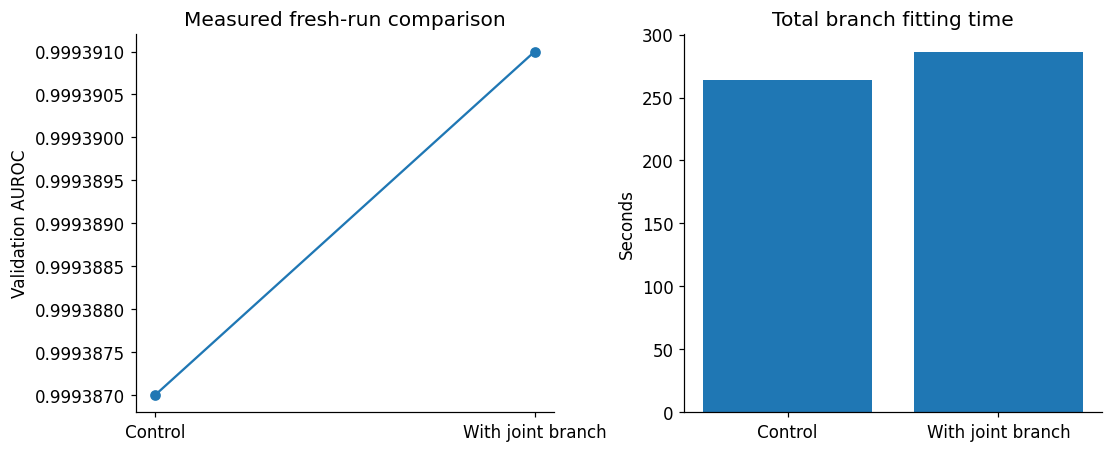

In [ ]:
control_p = development_predictions.loc[VAL_IDS,'control'].to_numpy()
candidate_p = development_predictions.loc[VAL_IDS,'probability'].to_numpy()
added_seconds = float(development_timings.set_index('Branch').loc['embedding_statistics_tree','Fit seconds'])
q5_results = pd.DataFrame([
    {'Configuration':'Fresh control ensemble','Validation AUROC':roc_auc_score(y_val,control_p),
     'Validation log loss':log_loss(y_val,control_p),'Additional fit seconds':0.,'Public AUROC':np.nan},
    {'Configuration':'Control + joint vector/statistics tree','Validation AUROC':roc_auc_score(y_val,candidate_p),
     'Validation log loss':log_loss(y_val,candidate_p),'Additional fit seconds':added_seconds,'Public AUROC':np.nan}])
total_fit_seconds = float(development_timings['Fit seconds'].sum())
q5_results['Total branch fit seconds'] = [total_fit_seconds-added_seconds,total_fit_seconds]
q5_results['Shared feature compute seconds'] = float(pd.DataFrame(feature_runtime)['Recorded compute seconds'].sum())
q5_results.to_csv(RUN_DIR/'tables/q5_comparison.csv',index=False)
display(q5_results)
print('Validation AUROC change:',roc_auc_score(y_val,candidate_p)-roc_auc_score(y_val,control_p))
print('Total branch fit seconds include representations and classifiers; shared feature time is separate.')
print('Search, prediction, loading and export time are not included; restored timings describe the original run.')
fig,axes = plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
axes[0].plot(['Control','With joint branch'],q5_results['Validation AUROC'],'o-')
axes[0].set(ylabel='Validation AUROC',title='Measured fresh-run comparison')
axes[0].ticklabel_format(axis='y',style='plain',useOffset=False)
axes[1].bar(['Control','With joint branch'],q5_results['Total branch fit seconds'])
axes[1].set(ylabel='Seconds',title='Total branch fitting time')
fig.savefig(RUN_DIR/'figures/q5_comparison.png',dpi=200,bbox_inches='tight')
plt.show()


### Q5.4 — Interpretation, limitations and next step
Validation AUROC changes from **0.999387** to **0.999391**, only **+0.000004**. Validation log loss decreases from **0.046086** to **0.035703**. The saved branch timings give **263.63 s** for the control and **285.90 s** for the candidate, with **22.27 s** added by PCA and the new tree. This supports a small observed ranking change and better probabilistic loss on this split, not a large or statistically demonstrated gain. The existing vector LR branch and earlier parameter selection limit interpretation as a clean embedding ablation. Shared feature extraction took about **33.0 minutes** and is not a per-branch cost. A useful next study would compare several predeclared splits or paired uncertainty estimates, while retaining a held-out assessment. The public score 0.98819 belongs to the complete final submission; no new control submission score is claimed here.


## Q6 — Code submission, reproducibility and AI assistance
### Q6.1 — Training/evaluation entrypoint and submission generation
**Entrypoint:** this notebook, executed from top to bottom. In Colab, use the Setup instructions and **Runtime → Run all**. The last export cell writes `submission.csv` under `OUTPUT_ROOT/runs/<RUN_KEY>/`; `OUTPUT_ROOT/latest_run.json` records its exact location. A matching cache permits repeated exports without retraining. Data and model files must not be included in the course PR.

**Local terminal example (Python 3.12 or newer):** run from the directory containing this notebook, with the supplied CSVs in `data/`. The package ranges below match the dependency cell; the exact reference environment is recorded in Setup. Local CPU is supported but a full local CPU run has not been verified end to end.
```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install 'numpy>=1.26,<3' 'pandas>=2.2,<3' 'scipy>=1.11,<2' 'scikit-learn==1.6.1' 'catboost==1.2.8' 'matplotlib>=3.5,<4' 'joblib>=1.4,<2' 'threadpoolctl>=3.5,<4' 'transformers==4.57.1' 'tokenizers>=0.22,<0.24' 'safetensors>=0.4,<1' 'torch>=2.6,<3' 'ipykernel>=6,<8' 'nbconvert>=7,<8'
python -m ipykernel install --user --name human-ai-group-1 --display-name 'Human or AI - Group 1'
mkdir -p outputs
HUMAN_AI_DATA_DIR="$PWD/data" HUMAN_AI_OUTPUT_DIR="$PWD/outputs" jupyter nbconvert --to notebook --execute --ExecutePreprocessor.kernel_name=human-ai-group-1 --ExecutePreprocessor.timeout=-1 --output Human_or_AI.executed.ipynb --output-dir outputs Human_or_AI_Full_Colab_Training.ipynb
```
The command runs training, validation experiments and final prediction. To copy its generated file to `./submission.csv`:
```bash
python -c "import json, pathlib, shutil; r=json.loads(pathlib.Path('outputs/latest_run.json').read_text()); shutil.copyfile(r['submission'], 'submission.csv'); print(pathlib.Path('submission.csv').resolve())"
```
Use a CUDA-enabled PyTorch installation appropriate for the machine when running on a local NVIDIA GPU. `HUMAN_AI_DEVICE=cpu` explicitly selects CPU. Seeds, split IDs, data hashes, dependency versions and final model manifests are saved with every run. Course PR: https://github.com/sekhari/human-or-ai-submissions/pull/17 (also listed in Q0 and on the report title page).

#### Final refit on all 10,000 true labels
The following cells refit every supervised vocabulary, NB weight, scaler, PCA and classifier on the full labeled set. They never replace the development predictions used in Q4. Q3 pseudo-labels remain a separate experiment and are not silently added to the final recipe.


In [ ]:
PHASE = 'final'
phase_fit_ids = train.id.to_numpy().copy()
phase_predict_ids = template.id.to_numpy().copy()
phase_y = indexed_train.loc[phase_fit_ids,'label'].to_numpy()
PHASE_DIR = RUN_DIR/'models'/PHASE
PHASE_DIR.mkdir(parents=True,exist_ok=True)
phase_signature = hashlib.sha256(json.dumps({'run_key':RUN_KEY,'ids':phase_fit_ids.tolist(),
    'labels':phase_y.tolist()},sort_keys=True).encode()).hexdigest()
phase_predictions = pd.DataFrame(index=pd.Index(phase_predict_ids,name='id'))
phase_timings = []
print('Refitting complete final system:',len(phase_fit_ids),'labeled rows')


Refitting complete final system: 10000 labeled rows


In [ ]:
# Fit text representations on this phase's labeled rows only.
fit_texts = text_by_id.loc[phase_fit_ids, 'normalized_text'].tolist()
shared_clean = None
sparse_models = {}
for family in SPARSE_FAMILIES:
    cache = PHASE_DIR / f'sparse_{family}.joblib'
    if REUSE_CURRENT_RUN and cache.is_file():
        bundle = joblib.load(cache)
        assert bundle['phase_signature'] == phase_signature
        assert bundle['family'] == family and bundle['run_key'] == RUN_KEY
        fit_seconds = bundle['fit_seconds']
        clean_loss, augmented_loss = bundle['train_log_loss'], bundle['augmented_log_loss']
        print(f'{PHASE}/{family}: restored this run; recorded fit {fit_seconds:.1f}s', flush=True)
    else:
        started = time.perf_counter()
        if family.startswith('clean_'):
            if shared_clean is None:
                word = TfidfVectorizer(**WORD_SETTINGS)
                char = TfidfVectorizer(**CHAR_SETTINGS)
                word_fit = word.fit_transform(fit_texts)
                char_fit = char.fit_transform(fit_texts)
                binary = hstack([.5 * word_fit, char_fit], format='csr')
                binary.data.fill(1.)
                positive = np.asarray(binary[phase_y == 1].sum(axis=0)).ravel().astype(float) + 1.
                negative = np.asarray(binary[phase_y == 0].sum(axis=0)).ravel().astype(float) + 1.
                ratio = np.log(positive / positive.sum() / (negative / negative.sum())).astype(np.float32)
                normalized_text_matrix = normalize(binary.multiply(ratio)).tocsr()
                style_scaler = StandardScaler().fit(style_table.loc[phase_fit_ids].to_numpy())
                scaled_style = style_scaler.transform(style_table.loc[phase_fit_ids].to_numpy())
                shared_clean = {'word':word,'char':char,'ratio':ratio,'scaler':style_scaler,
                    'text_matrix':normalized_text_matrix,'scaled_style':scaled_style,
                    'representation_seconds':time.perf_counter()-started}
                del binary, word_fit, char_fit
            bundle = {k:shared_clean[k] for k in ['word','char','ratio','scaler']}
            if family == 'clean_poly_0.1':
                poly = PolynomialFeatures(degree=2, include_bias=False)
                expanded = poly.fit_transform(np.clip(shared_clean['scaled_style'], -8, 8))
                poly_scaler = StandardScaler().fit(expanded)
                style_matrix = np.clip(poly_scaler.transform(expanded), -8, 8).astype(np.float32) * .1
                bundle.update(poly=poly, poly_scaler=poly_scaler)
            else:
                style_matrix = shared_clean['scaled_style'] * .3
            matrix = hstack([shared_clean['text_matrix'], csr_matrix(style_matrix)], format='csr')
        else:
            # BPE is learned on competition training text, not on validation/test text.
            bpe = Tokenizer(models.BPE(unk_token='[UNK]'))
            bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
            trainer = trainers.BpeTrainer(vocab_size=4000, min_frequency=2,
                special_tokens=['[UNK]'], initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
            bpe.train_from_iterator(fit_texts, trainer=trainer)
            encoded = [' '.join('t'+str(t) for t in item.ids) for item in bpe.encode_batch(fit_texts)]
            vectorizer = TfidfVectorizer(ngram_range=(1,3), min_df=2, max_features=250000,
                lowercase=False, token_pattern=r'(?u)\bt\d+\b', sublinear_tf=True, dtype=np.float32)
            binary = vectorizer.fit_transform(encoded)
            binary.data.fill(1.)
            positive = np.asarray(binary[phase_y == 1].sum(axis=0)).ravel().astype(float) + 1.
            negative = np.asarray(binary[phase_y == 0].sum(axis=0)).ravel().astype(float) + 1.
            ratio = np.log(positive / positive.sum() / (negative / negative.sum())).astype(np.float32)
            matrix = normalize(binary.multiply(ratio)).tocsr()
            bundle = {'tokenizer_json':bpe.to_str(),'vectorizer':vectorizer,'ratio':ratio}
            del binary

        # Mask only nonzero text entries; style columns retain their values.
        corrupted = matrix.copy().tocsr()
        positions = np.flatnonzero(corrupted.indices < len(bundle['ratio']))
        mask_seed = SEED + 1000 * len(phase_fit_ids) + 17 * SPARSE_FAMILIES.index(family)
        rng = np.random.default_rng(mask_seed)
        keep = rng.random(len(positions), dtype=np.float32) >= DROPOUT_RATE
        corrupted.data[positions] *= keep / (1. - DROPOUT_RATE)
        corrupted.eliminate_zeros()
        augmented = vstack([matrix, corrupted], format='csr')
        augmented_y = np.concatenate([phase_y, phase_y])
        sample_weight = np.full(len(augmented_y), .5)
        classifier = LogisticRegression(C=100., solver='liblinear', max_iter=5000,
                                         tol=1e-4, random_state=SEED)
        with threadpool_limits(limits=CPU_THREADS):
            classifier.fit(augmented, augmented_y, sample_weight=sample_weight)
        np.testing.assert_array_equal(classifier.classes_, [0,1])
        clean_loss = log_loss(phase_y, classifier.predict_proba(matrix)[:,1])
        augmented_loss = log_loss(augmented_y, classifier.predict_proba(augmented)[:,1], sample_weight=sample_weight)
        fit_seconds = time.perf_counter() - started
        bundle.update(classifier=classifier, family=family, phase_signature=phase_signature,
            run_key=RUN_KEY, fit_seconds=fit_seconds, mask_seed=mask_seed,
            training_rows=len(phase_fit_ids), dropout=DROPOUT_RATE,
            train_log_loss=float(clean_loss), augmented_log_loss=float(augmented_loss))
        temporary = cache.with_suffix('.tmp')
        joblib.dump(bundle, temporary, compress=3)
        temporary.replace(cache)
        # Use the persisted object for inference, so serialization is exercised.
        bundle = joblib.load(cache)
        del matrix, corrupted, augmented, augmented_y, sample_weight, positions, keep
        print(f'{PHASE}/{family}: trained in {fit_seconds:.1f}s; train log loss {clean_loss:.5f}', flush=True)

    # Transform and predict in batches to limit local memory use.
    predicted = []
    for begin in range(0, len(phase_predict_ids), 256):
        batch_ids = phase_predict_ids[begin:begin+256]
        texts = text_by_id.loc[batch_ids, 'normalized_text'].tolist()
        if family == 'bpe_nb':
            bpe = Tokenizer.from_str(bundle['tokenizer_json'])
            encoded = [' '.join('t'+str(t) for t in item.ids) for item in bpe.encode_batch(texts)]
            matrix = bundle['vectorizer'].transform(encoded)
        else:
            matrix = hstack([.5*bundle['word'].transform(texts),bundle['char'].transform(texts)],format='csr')
        matrix = matrix.copy()
        matrix.data.fill(1.)
        matrix = normalize(matrix.multiply(bundle['ratio'])).tocsr()
        if family != 'bpe_nb':
            raw_style = style_table.loc[batch_ids].to_numpy()
            if family == 'clean_poly_0.1':
                scaled = np.clip(bundle['scaler'].transform(raw_style), -8, 8)
                expanded = bundle['poly'].transform(scaled)
                style_matrix = np.clip(bundle['poly_scaler'].transform(expanded), -8, 8).astype(np.float32) * .1
            else:
                style_matrix = bundle['scaler'].transform(raw_style) * .3
            matrix = hstack([matrix,csr_matrix(style_matrix)],format='csr')
        predicted.append(bundle['classifier'].predict_proba(matrix)[:,1])
    phase_predictions[family] = np.concatenate(predicted)
    phase_timings.append({'Branch':family,'Fit seconds':fit_seconds,
        'Cost scope':'representation construction and classifier fit; shared word/char setup counted once',
        'Train log loss':clean_loss,'Augmented log loss':augmented_loss})
    sparse_models[family] = str(cache)
    del bundle, matrix
    gc.collect()
shared_clean = None
phase_predictions['sparse'] = sum(SPARSE_WEIGHTS[name]*phase_predictions[name] for name in SPARSE_FAMILIES)
assert np.isfinite(phase_predictions['sparse']).all()
display(pd.DataFrame(phase_timings))


final/clean_nbstyle_0.3: trained in 118.0s; train log loss 0.01085
final/clean_poly_0.1: trained in 93.8s; train log loss 0.00844
final/bpe_nb: trained in 37.6s; train log loss 0.01043


,Branch,Fit seconds,Cost scope,Train log loss,Augmented log loss
0,clean_nbstyle_0.3,118.043835,representation construction and classifier fit...,0.010846,0.010203
1,clean_poly_0.1,93.777570,representation construction and classifier fit...,0.008445,0.007959
2,bpe_nb,37.611265,representation construction and classifier fit...,0.010433,0.010087


In [ ]:
# Fit each dense branch; data-dependent transformations are inside the fitted bundle.
for branch, spec in DENSE_RECIPE.items():
    cache = PHASE_DIR / f'{branch}.joblib'
    if spec['view'] == 'embedding':
        fit_x = embeddings.loc[phase_fit_ids].to_numpy()
        predict_x = embeddings.loc[phase_predict_ids].to_numpy()
    elif spec['view'] == 'joint_embedding':
        fit_vectors = embeddings.loc[phase_fit_ids].to_numpy()
        predict_vectors = embeddings.loc[phase_predict_ids].to_numpy()
        fit_norms = np.linalg.norm(fit_vectors, axis=1, keepdims=True)
        predict_norms = np.linalg.norm(predict_vectors, axis=1, keepdims=True)
        assert (fit_norms > 0).all() and (predict_norms > 0).all()
        fit_vectors = (fit_vectors / fit_norms).astype(np.float32)
        predict_vectors = (predict_vectors / predict_norms).astype(np.float32)
    else:
        fit_x = stats.loc[phase_fit_ids, VIEW_COLUMNS[spec['view']]].to_numpy()
        predict_x = stats.loc[phase_predict_ids, VIEW_COLUMNS[spec['view']]].to_numpy()

    if REUSE_CURRENT_RUN and cache.is_file():
        saved = joblib.load(cache)
        assert saved['phase_signature'] == phase_signature and saved['spec'] == spec
        assert saved['run_key'] == RUN_KEY
        model = saved['model']
        fit_seconds = saved['fit_seconds']
        print(f'{PHASE}/{branch}: restored this run; recorded fit {fit_seconds:.1f}s', flush=True)
    else:
        started = time.perf_counter()
        fitted_pca = None
        if spec['kind'] == 'polynomial_lr':
            model = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2,include_bias=False),
                StandardScaler(), LogisticRegression(C=spec['C'],solver='lbfgs',
                    max_iter=spec['max_iter'],tol=spec['tol'],random_state=SEED))
        elif spec['kind'] == 'embedding_lr':
            model = make_pipeline(Normalizer(),StandardScaler(),
                LogisticRegression(C=spec['C'],solver='lbfgs',max_iter=spec['max_iter'],
                    tol=spec['tol'],random_state=SEED))
        else:
            if spec['kind'] == 'embedding_tree':
                fitted_pca = PCA(n_components=32,svd_solver='randomized',random_state=SEED)
                with threadpool_limits(limits=CPU_THREADS):
                    fitted_pca.fit(fit_vectors)
                fit_pc = fitted_pca.transform(fit_vectors)[:, :16]
                fit_x = np.hstack([stats.loc[phase_fit_ids].to_numpy(),fit_pc])
            model = CatBoostClassifier(depth=spec['depth'],**TREE_SETTINGS)
        with threadpool_limits(limits=CPU_THREADS):
            model.fit(fit_x,phase_y)
        fit_seconds = time.perf_counter()-started
        np.testing.assert_array_equal(model.classes_,[0,1])
        train_loss = float(log_loss(phase_y,model.predict_proba(fit_x)[:,1]))
        saved = {'model':model,'pca':fitted_pca,'spec':spec,'run_key':RUN_KEY,
            'phase_signature':phase_signature,'training_rows':len(phase_fit_ids),
            'fit_seconds':fit_seconds,'train_log_loss':train_loss}
        temporary = cache.with_suffix('.tmp')
        joblib.dump(saved,temporary,compress=3)
        temporary.replace(cache)
        restored = joblib.load(cache)
        np.testing.assert_allclose(restored['model'].predict_proba(fit_x[:16]),
                                   model.predict_proba(fit_x[:16]),rtol=0,atol=1e-12)
        saved,model = restored,restored['model']
        print(f'{PHASE}/{branch}: trained in {fit_seconds:.1f}s; train log loss {train_loss:.5f}',flush=True)
    if spec['kind'] == 'embedding_tree':
        predict_pc = saved['pca'].transform(predict_vectors)[:, :16]
        predict_x = np.hstack([stats.loc[phase_predict_ids].to_numpy(),predict_pc])
    p = model.predict_proba(predict_x)[:,1]
    assert p.shape==(len(phase_predict_ids),) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    phase_predictions[branch] = p
    phase_timings.append({'Branch':branch,'Fit seconds':fit_seconds,
        'Cost scope':'classifier and fitted transformations; frozen feature extraction excluded',
        'Train log loss':saved['train_log_loss'],'Augmented log loss':np.nan})
display(pd.DataFrame(phase_timings))


final/norm_lr: trained in 11.4s; train log loss 0.19500
final/embedding_lr: trained in 3.3s; train log loss 0.17099
final/raw_lr: trained in 3.9s; train log loss 0.12491
final/joint_lr: trained in 4.6s; train log loss 0.10971
final/structure_tree: trained in 15.6s; train log loss 0.01944
final/dual_lm_tree: trained in 5.9s; train log loss 0.06576
final/all_features_tree: trained in 21.7s; train log loss 0.01429
final/embedding_statistics_tree: trained in 24.3s; train log loss 0.01336


,Branch,Fit seconds,Cost scope,Train log loss,Augmented log loss
0,clean_nbstyle_0.3,118.043835,representation construction and classifier fit...,0.010846,0.010203
1,clean_poly_0.1,93.777570,representation construction and classifier fit...,0.008445,0.007959
2,bpe_nb,37.611265,representation construction and classifier fit...,0.010433,0.010087
3,norm_lr,11.359621,classifier and fitted transformations; frozen ...,0.194997,NaN
4,embedding_lr,3.268111,classifier and fitted transformations; frozen ...,0.170985,NaN
5,raw_lr,3.854594,classifier and fitted transformations; frozen ...,0.124907,NaN
6,joint_lr,4.641570,classifier and fitted transformations; frozen ...,0.109712,NaN
7,structure_tree,15.618398,classifier and fitted transformations; frozen ...,0.019443,NaN
8,dual_lm_tree,5.873547,classifier and fitted transformations; frozen ...,0.065761,NaN
9,all_features_tree,21.706122,classifier and fitted transformations; frozen ...,0.014293,NaN


In [ ]:
# Expand the same nested recipe used by the historical system.
p_base = .6*phase_predictions['sparse'] + .4*phase_predictions.norm_lr
phase_predictions['legacy_lr'] = (
    .9*(.7*(.8*p_base + .2*phase_predictions.embedding_lr)
         + .3*phase_predictions.raw_lr) + .1*phase_predictions.joint_lr)
phase_predictions['control'] = (
    .16*phase_predictions.legacy_lr + .24*phase_predictions.structure_tree
    + .10*phase_predictions.dual_lm_tree + .50*phase_predictions.all_features_tree)
phase_predictions['probability'] = sum(
    FINAL_WEIGHTS[name]*phase_predictions[name] for name in FINAL_WEIGHTS)
np.testing.assert_allclose(phase_predictions.probability,
    .5*phase_predictions.control + .5*phase_predictions.embedding_statistics_tree,atol=1e-12,rtol=0)
assert np.isfinite(phase_predictions.to_numpy()).all()
assert ((phase_predictions>=0)&(phase_predictions<=1)).all().all()
print(PHASE,'fusion complete:',phase_predictions.shape)

final_predictions = phase_predictions.copy()
final_timings = pd.DataFrame(phase_timings)
final_predictions.to_csv(RUN_DIR/'tables/final_test_branches.csv')
final_timings.to_csv(RUN_DIR/'tables/final_training_times.csv',index=False)
display(final_timings)


final fusion complete: (3000, 15)


,Branch,Fit seconds,Cost scope,Train log loss,Augmented log loss
0,clean_nbstyle_0.3,118.043835,representation construction and classifier fit...,0.010846,0.010203
1,clean_poly_0.1,93.777570,representation construction and classifier fit...,0.008445,0.007959
2,bpe_nb,37.611265,representation construction and classifier fit...,0.010433,0.010087
3,norm_lr,11.359621,classifier and fitted transformations; frozen ...,0.194997,NaN
4,embedding_lr,3.268111,classifier and fitted transformations; frozen ...,0.170985,NaN
5,raw_lr,3.854594,classifier and fitted transformations; frozen ...,0.124907,NaN
6,joint_lr,4.641570,classifier and fitted transformations; frozen ...,0.109712,NaN
7,structure_tree,15.618398,classifier and fitted transformations; frozen ...,0.019443,NaN
8,dual_lm_tree,5.873547,classifier and fitted transformations; frozen ...,0.065761,NaN
9,all_features_tree,21.706122,classifier and fitted transformations; frozen ...,0.014293,NaN


#### Export submission.csv and its provenance
This export changes the filename, not the probability-generation recipe. The original `submission_full_local.csv` is preserved. A reported public score is associated with the new file only if its bytes match that preserved reference CSV in the recorded reference run. A differing or fresh file has no measured public score until submitted. The new export cell must be run before the canonical file exists.


In [ ]:
# Historical submission metadata.
SCORED_RUN = {
    "run_key": "89edcbdd288ce05a",
    "public_auc": 0.98819,
    "submission_name": "submission_full_local.csv",
    "source": "Previously reported Kaggle result",
}
PRIVATE_AUC = None

In [ ]:
new_submission = template.copy()
new_submission.iloc[:,1] = final_predictions.loc[template.id,'probability'].to_numpy()
assert new_submission.columns.tolist()==template.columns.tolist()
np.testing.assert_array_equal(new_submission.id,template.id)
p = new_submission.iloc[:,1].to_numpy()
assert len(p)==len(test) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
SUBMISSION_PATH = RUN_DIR/'submission.csv'
new_submission.to_csv(SUBMISSION_PATH,index=False)
model_files = {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in PHASE_DIR.glob('*.joblib')}
# Associate a reported score only with a byte-identical preserved reference CSV.
reference_path = RUN_DIR/SCORED_RUN['submission_name']
reference_match = (RUN_KEY == SCORED_RUN['run_key'] and reference_path.is_file()
    and hashlib.sha256(reference_path.read_bytes()).hexdigest() == hashlib.sha256(SUBMISSION_PATH.read_bytes()).hexdigest())
manifest = {'run_key':RUN_KEY,'feature_key':FEATURE_KEY,'training_rows':len(train),
    'test_rows':len(test),'data_hashes':DATA_HASHES,'final_weights':FINAL_WEIGHTS,
    'sparse_weights':SPARSE_WEIGHTS,'dense_recipe':DENSE_RECIPE,'model_files_sha256':model_files,
    'model_folder':str(PHASE_DIR),'feature_folder':str(FEATURE_DIR),
    'submission_file':str(SUBMISSION_PATH),'submission_sha256':hashlib.sha256(SUBMISSION_PATH.read_bytes()).hexdigest(),
    'public_auc':SCORED_RUN['public_auc'] if reference_match else None,'private_auc':PRIVATE_AUC,
    'reference_run':SCORED_RUN,'matches_preserved_scored_csv':reference_match,
    'score_note':'Team-reported reference score applies only when the preserved scored CSV matches exactly.',
    'environment':ENVIRONMENT}
(RUN_DIR/'inference_manifest.json').write_text(json.dumps(manifest,indent=2))
(OUTPUT_ROOT/'latest_run.json').write_text(json.dumps({'run_dir':str(RUN_DIR),
            'submission':str(SUBMISSION_PATH)},indent=2))
display(new_submission.head())
print('NEW submission:',SUBMISSION_PATH)
print('Saved final model bundles:',len(model_files))
print('Matches preserved 0.98819 CSV:',reference_match)
print('Public AUROC associated with this exact CSV:',manifest['public_auc'])

if DOWNLOAD_SUBMISSION:
    from google.colab import files
    files.download(str(SUBMISSION_PATH))
else:
    print('The submission is saved at:', SUBMISSION_PATH)


,id,label
0,13001,0.999506
1,13002,0.014735
2,13003,0.099915
3,13004,0.004909
4,13005,0.997994


NEW submission: /content/drive/MyDrive/human_or_ai/outputs/full_colab_training/runs/3bd0a8a7c0bd60ce/submission.csv
Saved final model bundles: 11
Matches preserved 0.98819 CSV: False
Public AUROC associated with this exact CSV: None


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Check the experiment tables and exported submission.
evidence = pd.DataFrame([
    {
        "Question": question,
        "File": filename,
        "Available": (RUN_DIR / "tables" / filename).is_file(),
    }
    for question, filename in [
        ("Q1", "q1_model_comparison.csv"),
        ("Q2", "q2_learning_curve.csv"),
        ("Q3", "q3_comparison.csv"),
        ("Q4", "q4_final_model_metrics.csv"),
        ("Q5", "q5_comparison.csv"),
    ]
])

evidence.to_csv(
    RUN_DIR / "tables" / "report_evidence_index.csv",
    index=False,
)
display(evidence)

status = {
    "computed_evidence_complete": bool(evidence["Available"].all()),
    "submission_exists": SUBMISSION_PATH.is_file(),
    "submission_path": str(SUBMISSION_PATH),
    "public_auc": manifest["public_auc"],
    "private_auc": PRIVATE_AUC,
}

(RUN_DIR / "report_status.json").write_text(
    json.dumps(status, indent=2),
    encoding="utf-8",
)

print("All experiment tables available:", status["computed_evidence_complete"])
print("Submission exists:", status["submission_exists"])
print("Submission:", SUBMISSION_PATH)

,Question,File,Available
0,Q1,q1_model_comparison.csv,True
1,Q2,q2_learning_curve.csv,True
2,Q3,q3_comparison.csv,True
3,Q4,q4_final_model_metrics.csv,True
4,Q5,q5_comparison.csv,True


All experiment tables available: True
Submission exists: True
Submission: /content/drive/MyDrive/human_or_ai/outputs/full_colab_training/runs/3bd0a8a7c0bd60ce/submission.csv


### Q6.2 — Development changes
1. **Joint feature modeling and reproducible prediction** ([`36176b3`](https://github.com/sekhari/human-or-ai-submissions/pull/17/commits/36176b3e559aecfd244e46d0d1b84194347fcc65)): added the CatBoost on the 122 statistics plus 16 GPT-2 PCA components (Q5) and the final refit and export. Validation AUROC changed by only +0.000004 while log loss fell from 0.046 to 0.036, which showed that the fixed validation split is nearly saturated: AUROC alone barely separates our later variants, so calibration and paired uncertainty matter.
2. **Unlabeled learning and error analysis** ([`d3bcef2`](https://github.com/sekhari/human-or-ai-submissions/pull/17/commits/d3bcef23f0bc148434ced63230f0847999489500)): added confidence-based pseudo-labeling (Q3) and the validation error analysis (Q4). 2,747 confident pseudo-labels moved validation AUROC from 0.999280 to 0.999266, so the final recipe uses only true labels; the ten sampled errors include web-formatted or entity-dense AI texts and formal human prose.
3. **TF-IDF representation baseline** ([`d106fd3`](https://github.com/sekhari/human-or-ai-submissions/pull/17/commits/d106fd377bb6fb7452aeb4b7d0409488bb879c57)): re-ran our first representation, word TF-IDF 1–2-grams with LR, under the Q1 protocol: training AUROC 1.000 but validation 0.943, against 0.996 for LR on the 122 frozen-model statistics (train–validation gap 0.057 vs 0.003). This documents why we moved from topic-bound n-gram counts to language-model predictability features.

### Q6.3 — AI assistance
Claude and ChatGPT (including Codex) were used during development. We used them as a first pass to generate and debug code; all code was then checked manually for correctness and to make sure we understood it. Approaches were brainstormed together with the AI tools and chosen by us. Two saved notebook outputs, the TF-IDF baseline table and the updated Q1 comparison figure, were generated by Claude from our `train.csv` with the same split and folds. The Q4.3 failure hypotheses started as AI-assisted drafts, which we reviewed against the full texts. Finally, AI was used to format and revise the write-up. No external LLM API was used to label or predict test passages, and no hidden labels were retrieved.